# BJT and MOSFET Circuits

## Prerequisites

In [1]:
# HIDE/SHOW
# ! pip install -U numpy
# ! pip install -U matplotlib

## Visualization in Python

The folder of this notebook holds a small package, `schematic`, with the symbol geometry and a matplotlib renderer. Labels are set in Computer Modern through matplotlib's mathtext, so no TeX installation is needed.

In [2]:
# HIDE/SHOW
import warnings
warnings.filterwarnings('ignore')

import matplotlib.pyplot as plt
%matplotlib inline
%config InlineBackend.figure_formats = ['svg']
%config InlineBackend.print_figure_kwargs = {'bbox_inches': None}   # keep every figure at its full width
plt.rcParams['svg.hashsalt'] = 'fme'            # reproducible SVG output

from schematic import Transistor, BJT, MOSFET, RED, show, symbol_sheet

IN, OUT = 'V_in', 'V_out'

## Utilizations

A circuit is a function of a drawing context `c`. `c.transistor(kind, at, anchor)` places a transistor of the class the drawing is made with. There are two classes, `BJT` and `MOSFET`, both derived from `Transistor`, so one function draws both columns.

| | BJT | MOSFET |
|---|---|---|
| **Class** | `BJT(Transistor)` | `MOSFET(Transistor)` |
| **Kind** `'n'`, `'p'` | npn, pnp | NMOS, PMOS |
| **Terminals** | `.b`, `.c`, `.e`: base, collector, emitter | `.g`, `.d`, `.s`: gate, drain, source |
| **Shared names** `.bg`, `.cd`, `.es` | give `.b`, `.c`, `.e` | give `.g`, `.d`, `.s` |
| **Name** `name=1` | $Q_1$ | $M_1$ |
| **Supply** `c.supply(p)` | $V_{CC}$ | $V_{DD}$ |
| **Size** `.size(text)` | draws nothing | writes a $W/L$ label beside the device |

The circuit functions use only the shared names, which read *base or gate*, *collector or drain* and *emitter or source*. `c.w(p0, p1, ...)` draws a wire, `c.dot(p)` a node, `c.port(p, label, side)` an open terminal, `c.gnd(p)` a ground, `c.ac(p)` an ac ground, `c.res(p, label)` a resistor and `c.load(p)` a load. `c.look(p, into, side, label)` marks the impedance seen at `p` with a red arrow that has a 90-degree corner; `form='low'` and `form='long'` give its two other forms. `c.pick(a, b)` returns `a` in a BJT drawing and `b` in a MOSFET drawing, and `t.note(t.ideal)` writes $V_A=\infty$ or $\lambda=0$ beside a transistor. `c.chain([...], x, y)` places a series stack of transistors, and `c.bus([...], x)` ties their bases or gates together. Coordinates are pixels on a 10-px grid with $y$ pointing down. Before drawing, all wire pieces and symbol leads are merged into continuous connectors.

`show(a, b, notes=[...])` draws the circuits `a` and `b` as two rows: their names in the first column, then the drawing made with `BJT` and the drawing made with `MOSFET`. `notes` holds the text that goes right under the drawings, for every circuit a pair `(BJT, MOSFET)` or one text for both. The first docstring line gives the names, as `BJT name | MOSFET name` where the two differ. A name `-` means that the circuit has no such version; that cell says so, and its note says why. Every drawing is centred in its cell on one vertical line: the main route of its transistors or, where two transistors stand side by side, the middle between them; `c.center(x)` picks another line. The cells are equally wide in every figure and every drawing has the same size, so the drawings line up down the whole page.

In [3]:
# HIDE/SHOW
def capacitor_to_ground(c, node):
    """second transistor, connected as a capacitor from `node` to ground"""
    t2 = c.transistor('n', (node[0], node[1] + 40), 'bg', side='right', rot=3, name=2)
    c.w(node, t2.bg)
    yb = t2.cd[1] + 20
    c.w(t2.cd, (t2.cd[0], yb), (t2.es[0], yb), t2.es)
    c.dot((node[0], yb)); c.w((node[0], yb), (node[0], yb + 10)); c.gnd((node[0], yb + 10))


def pass_device_and_capacitor(c, control, resistance=None):
    """first transistor as a pass device from the input to a node that the second one loads as a capacitor;
    `resistance` names the resistance of the pass device, if the note of the circuit uses it"""
    t1 = c.transistor('n', (0, 0), 'cd', side='right', rot=3, name=1)
    c.w(t1.cd, (-30, 0)); c.port((-30, 0), IN, 'l')
    if resistance:
        c.look((-30, 0), 'r', 'd', resistance)
    c.w(t1.bg, (t1.bg[0], t1.bg[1] - 20)); c.port((t1.bg[0], t1.bg[1] - 20), control, 't')
    node = (115, 0)
    c.w(t1.es, node); c.dot(node); c.w(node, (180, 0)); c.port((180, 0), OUT, 'r')
    capacitor_to_ground(c, node)


def op_amp(c, blocks):
    """The first `blocks` blocks of a two-stage op amp.  Every block is a circuit from further up:
    1 differential pair, 2 current source in its tail, 3 current mirror as its load,
    4 second stage with a current-source load, 5 current mirror that supplies both bias currents.
    The circuit is drawn narrow, so that all of it fits a cell at the size of every other drawing.
    The bias line runs above the lowest transistors and crosses the lead of the tail source;
    it goes down in line with the two vertical lines of the pair.  No wire runs below the ground symbols."""
    c.center(50)                                                                   # every row is aligned on the pair
    t1 = c.transistor('n', (0, 0), 'cd', name=1, lbl='r')                          # 1: the pair
    t2 = c.transistor('n', (100, 0), 'cd', side='right', name=2, lbl='l')
    c.port(t1.bg, 'V_1', 't'); c.port(t2.bg, 'V_2', 't')
    tail = (50, 100)
    c.w(t1.es, (0, 100), (100, 100), t2.es); c.dot(tail)
    if blocks < 2:
        c.w(tail, (50, 140)); c.port((50, 140), 'I_bias', 'b')
    else:                                                                          # 2: the tail current source
        t5 = c.transistor('n', (50, 150), 'cd', name=5)
        c.w(tail, t5.cd); c.w(t5.es, (50, 250)); c.gnd((50, 250))
        bias = (0, 190)                                                            # the gate node of the bias transistors, under the left line of the pair
        line = (tail[1] + t5.lead('cd')[1]) / 2                                    # bias line: half-way down the tail lead
        c.w(t5.bg, bias)
    if blocks < 3:
        c.w(t1.cd, (0, -40)); c.port((0, -40), 'I_1', 'r')
        c.w(t2.cd, (100, -40)); c.port((100, -40), 'I_2', 'r')
    else:                                                                          # 3: the current-mirror load
        t3 = c.transistor('p', (0, -100), 'es', side='right', name=3, lbl='l')
        t4 = c.transistor('p', (100, -100), 'es', name=4, lbl='r')
        c.w(t3.cd, t1.cd); c.w(t4.cd, t2.cd)
        c.w(t3.bg, t4.bg); c.dot((50, -60)); c.w((50, -60), (50, -10), (0, -10)); c.dot((0, -10))
        rail = 155 if blocks > 3 else 100
        c.w(t3.es, (0, -120), (rail, -120)); c.w(t4.es, (100, -120)); c.dot((50, -120))
        c.w((50, -120), (50, -160)); c.supply((50, -160))                         # as far above the rail as a ground hangs below
        first = (100, -10); c.dot(first)
    if blocks == 3:
        c.w(first, (160, -10)); c.port((160, -10), OUT, 'r'); c.look((160, -10), 'l', 'u', 'R_out')
    if blocks > 3:                                                                 # 4: the second stage
        t6 = c.transistor('p', (155, -50), 'es', name=6)                         # its input level with the first output
        t7 = c.transistor('n', (155, 150), 'cd', name=7)
        c.dot((100, -120)); c.w((155, -120), t6.es)
        c.w(first, t6.bg)
        c.w(t6.cd, t7.cd); c.w(t7.es, (155, 250)); c.gnd((155, 250))
        c.w(bias, (bias[0], line), (100, line), (100, t7.bg[1]), t7.bg); c.dot(bias)   # up, across, and down under the right line of the pair
        out = (155, 90); c.dot(out); c.w(out, (185, 90)); c.port((185, 90), OUT, 't')    # half-way between 6 and 7
    if blocks == 4:
        c.look((185, 90), 'l', 'd', 'R_out', nudge=-14)             # the arrow ends short of the second stage
    if 2 <= blocks < 5:
        c.w(bias, (-30, 190)); c.port((-30, 190), 'V_bias', 'l')
    if blocks == 5:                                                                # 5: the bias mirror
        t8 = c.transistor('n', (-50, 150), 'cd', side='right', name=8, lbl='l')
        c.w(t8.es, (-50, 250)); c.gnd((-50, 250))
        c.w(t8.bg, bias)
        c.w(t8.cd, (-50, 90)); c.port((-50, 90), 'I_ref', 'l')
        c.dot((-50, line)); c.w((-50, line), (bias[0], line)); c.dot((bias[0], line))    # the bias line starts at the diode

## What are Transistors?

- Transistors are three-terminal devices in which the voltage between two terminals controls the current through the third.
- In a bipolar junction transistor (BJT) the base-emitter voltage $V_{BE}$ controls the collector current $I_C$.
- In a MOS field-effect transistor (MOSFET) the gate-source voltage $V_{GS}$ controls the drain current $I_D$.

## Types of Transistors

- n-type transistors: npn BJT and NMOS FET
- p-type transistors: pnp BJT and PMOS FET, with all voltages and currents reversed

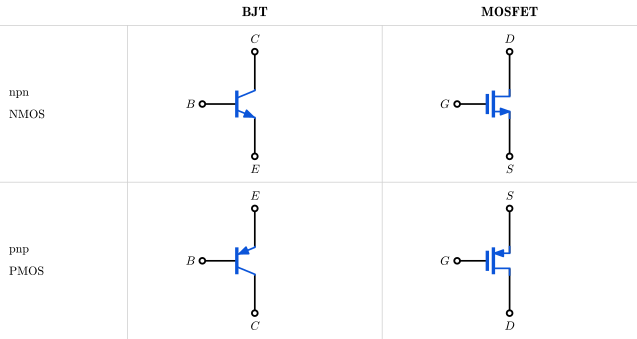

In [4]:
# HIDE/SHOW
def n_type(c):
    """npn | NMOS"""
    t = c.transistor('n', (0, 0), 'cd')
    c.w(t.cd, (0, -30)); c.port((0, -30), t.pin('cd'), 't')
    c.w(t.es, (0, 110)); c.port((0, 110), t.pin('es'), 'b')
    c.w(t.bg, (t.bg[0] - 30, 40)); c.port((t.bg[0] - 30, 40), t.pin('bg'), 'l')


def p_type(c):
    """pnp | PMOS"""
    t = c.transistor('p', (0, 0), 'es')
    c.w(t.es, (0, -30)); c.port((0, -30), t.pin('es'), 't')
    c.w(t.cd, (0, 110)); c.port((0, 110), t.pin('cd'), 'b')
    c.w(t.bg, (t.bg[0] - 30, 40)); c.port((t.bg[0] - 30, 40), t.pin('bg'), 'l')

show(n_type, p_type)

The two columns translate into each other term by term:

| | BJT | MOSFET |
|---|---|---|
| **Terminals** | base $B$, collector $C$, emitter $E$ | gate $G$, drain $D$, source $S$ |
| **Control voltage** | $V_{BE}$ | $V_{GS}$ |
| **Current law** | $I_C=I_S\,e^{V_{BE}/V_T}$ in the active region | $I_D=\tfrac12\mu_nC_{ox}\tfrac{W}{L}(V_{GS}-V_{TH})^2$ in saturation |
| **Transconductance** | $g_m=I_C/V_T$ | $g_m=2I_D/(V_{GS}-V_{TH})$ |
| **Output resistance** | $r_O=V_A/I_C$ | $r_O=1/(\lambda I_D)$ |
| **Control current** | $I_B=I_C/\beta$ | $I_G=0$ |
| **Input resistance** | $r_\pi=\beta/g_m$ | infinite |
| **Size** | emitter area, through $I_S$ | $W/L$ |
| **Names** | $Q_1$, $Q_2$, supply $V_{CC}$ | $M_1$, $M_2$, supply $V_{DD}$ |

$V_T=kT/q$ is the thermal voltage, about 26 mV at room temperature, and $V_{TH}$ is the threshold voltage of a MOSFET. All relations on this page are first-order: $r_O$ and $\beta$ are taken as infinite unless they appear, and the body effect is neglected.

## Connections of One Transistor

### Eight Roles

Eight roles of one transistor are used on this page. Most circuits of two transistors put two of them together.

#### Amplifier and Follower

The input drives the base or gate. The output is taken at the collector or drain (amplifier), or at the emitter or source (follower).

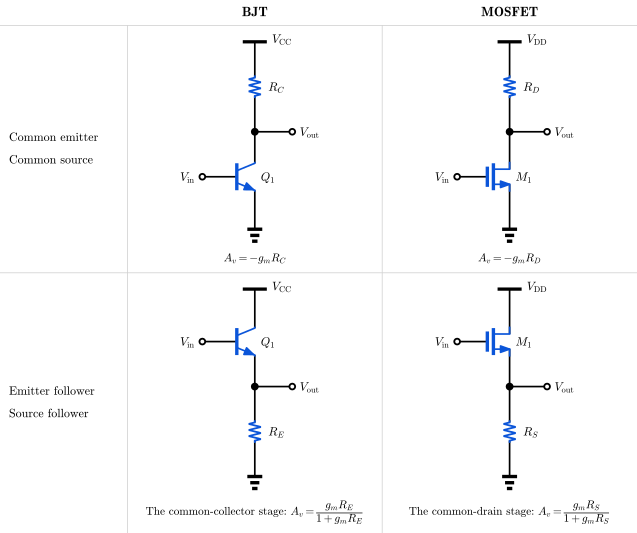

In [5]:
# HIDE/SHOW
def role_amplifier(c):
    """Common emitter | Common source"""
    t1 = c.transistor('n', (0, 0), 'cd', name=1)
    c.supply((0, -130)); c.w((0, -130), (0, -110))
    out = (0, -20)
    c.w(c.res((0, -110), 'R_' + t1.pin('cd')), t1.cd); c.dot(out)
    c.w(out, (50, -20)); c.port((50, -20), OUT, 'r')
    c.w(t1.es, (0, 100)); c.gnd((0, 100))
    c.w(t1.bg, (t1.bg[0] - 30, 40)); c.port((t1.bg[0] - 30, 40), IN, 'l')


def role_follower(c):
    """Emitter follower | Source follower"""
    t1 = c.transistor('n', (0, 0), 'cd', name=1)
    c.supply((0, -20)); c.w((0, -20), t1.cd)
    out = (0, 100)
    c.w(t1.es, (0, 130)); c.dot(out)
    c.w(out, (50, 100)); c.port((50, 100), OUT, 'r')
    c.w(c.res((0, 130), 'R_' + t1.pin('es')), (0, 210)); c.gnd((0, 210))
    c.w(t1.bg, (t1.bg[0] - 30, 40)); c.port((t1.bg[0] - 30, 40), IN, 'l')

show(role_amplifier, role_follower, notes=[
    ('$A_v=-g_mR_C$',
     '$A_v=-g_mR_D$'),
    (r'The common-collector stage: $A_v=\dfrac{g_mR_E}{1+g_mR_E}$',
     r'The common-drain stage: $A_v=\dfrac{g_mR_S}{1+g_mR_S}$')])

#### Current Buffer and Current Source

The base or gate is held at a fixed voltage. A current pushed into the emitter or source comes out of the collector or drain (current buffer). With the emitter or source grounded, the device sets the current itself (current source).

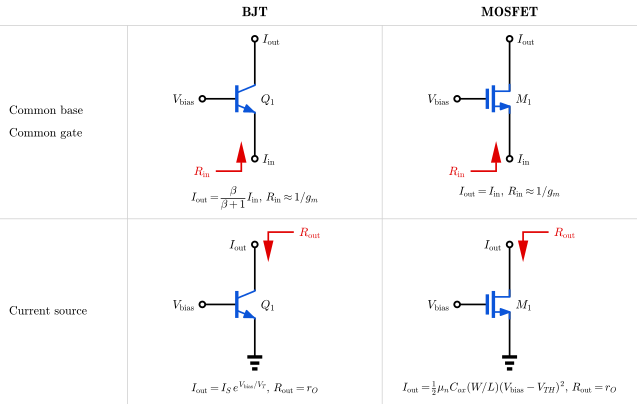

In [6]:
# HIDE/SHOW
def role_current_buffer(c):
    """Common base | Common gate"""
    t1 = c.transistor('n', (0, 0), 'cd', name=1)
    c.w(t1.cd, (0, -40)); c.port((0, -40), 'I_out', 'r')
    c.w(t1.es, (0, 120)); c.port((0, 120), 'I_in', 'r'); c.look((0, 120), 'u', 'l', 'R_in')
    c.w(t1.bg, (t1.bg[0] - 30, 40)); c.port((t1.bg[0] - 30, 40), 'V_bias', 'l')


def role_current_source(c):
    """Current source"""
    t1 = c.transistor('n', (0, 0), 'cd', name=1)
    c.w(t1.cd, (0, -40)); c.port((0, -40), 'I_out', 'l'); c.look((0, -40), 'd', 'r', 'R_out')
    c.w(t1.es, (0, 100)); c.gnd((0, 100))
    c.w(t1.bg, (t1.bg[0] - 30, 40)); c.port((t1.bg[0] - 30, 40), 'V_bias', 'l')

show(role_current_buffer, role_current_source, notes=[
    (r'$I_\mathrm{out}=\dfrac{\beta}{\beta+1}I_\mathrm{in}$, $R_\mathrm{in}\approx1/g_m$',
     r'$I_\mathrm{out}=I_\mathrm{in}$, $R_\mathrm{in}\approx1/g_m$'),
    (r'$I_\mathrm{out}=I_S\,e^{V_\mathrm{bias}/V_T}$, $R_\mathrm{out}=r_O$',
     r'$I_\mathrm{out}=\frac{1}{2}\mu_nC_{ox}(W/L)(V_\mathrm{bias}-V_{TH})^2$, $R_\mathrm{out}=r_O$')])

#### Diode and Switch

With the base tied to the collector, or the gate to the drain, the transistor is a two-terminal diode. Driven fully on and off, it is a switch.

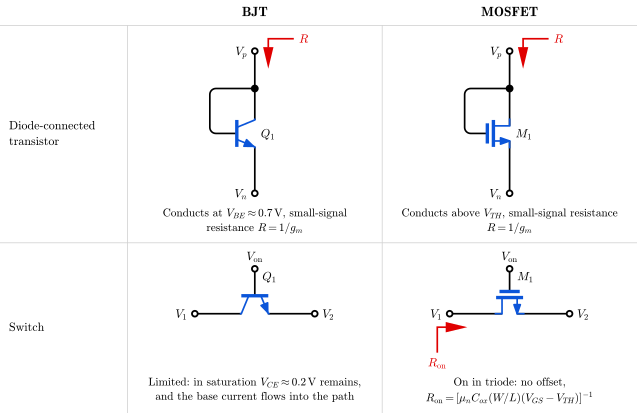

In [7]:
# HIDE/SHOW
def role_diode(c):
    """Diode-connected transistor"""
    t1 = c.transistor('n', (0, 0), 'cd', name=1)
    top = (0, -20)
    c.w(t1.cd, (0, -70)); c.dot(top); c.port((0, -70), 'V_p', 'l'); c.look((0, -70), 'd', 'r', 'R')
    c.w(t1.bg, (t1.bg[0] - 20, 40), (t1.bg[0] - 20, -20), top)
    c.w(t1.es, (0, 120)); c.port((0, 120), 'V_n', 'l')


def role_switch(c):
    """Switch"""
    t1 = c.transistor('n', (0, 0), 'cd', side='right', rot=3, name=1)
    c.w(t1.cd, (t1.cd[0] - 40, 0)); c.port((t1.cd[0] - 40, 0), 'V_1', 'l')
    c.w(t1.es, (t1.es[0] + 40, 0)); c.port((t1.es[0] + 40, 0), 'V_2', 'r')
    c.w(t1.bg, (t1.bg[0], t1.bg[1] - 20)); c.port((t1.bg[0], t1.bg[1] - 20), 'V_on', 't')
    if c.device is MOSFET:                                  # only the MOSFET is a resistance when it is on
        c.look((t1.cd[0] - 40, 0), 'r', 'd', 'R_on')

show(role_diode, role_switch, notes=[
    (r'Conducts at $V_{BE}\approx0.7\,\mathrm{V}$, small-signal resistance $R=1/g_m$',
     'Conducts above $V_{TH}$, small-signal resistance $R=1/g_m$'),
    (r'Limited: in saturation $V_{CE}\approx0.2\,\mathrm{V}$ remains, and the base current flows into the path',
     r'On in triode: no offset, $R_\mathrm{on}=\left[\mu_nC_{ox}(W/L)(V_{GS}-V_{TH})\right]^{-1}$')])

#### Resistor and Capacitor

A transistor can also stand in for a passive element. This is where the two devices differ most.

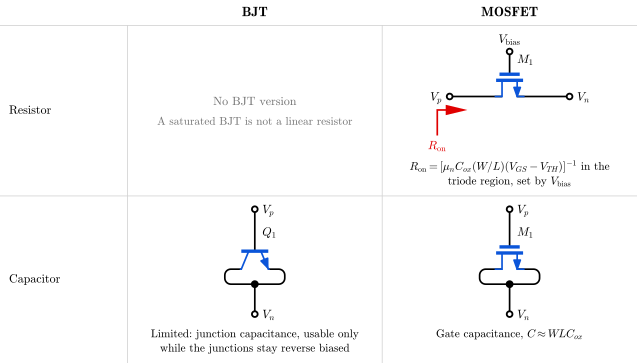

In [8]:
# HIDE/SHOW
def role_resistor(c):
    """- | Resistor"""
    t1 = c.transistor('n', (0, 0), 'cd', side='right', rot=3, name=1)
    c.w(t1.cd, (t1.cd[0] - 40, 0)); c.port((t1.cd[0] - 40, 0), 'V_p', 'l'); c.look((t1.cd[0] - 40, 0), 'r', 'd', 'R_on')
    c.w(t1.es, (t1.es[0] + 40, 0)); c.port((t1.es[0] + 40, 0), 'V_n', 'r')
    c.w(t1.bg, (t1.bg[0], t1.bg[1] - 20)); c.port((t1.bg[0], t1.bg[1] - 20), 'V_bias', 't')


def role_capacitor(c):
    """Capacitor"""
    t1 = c.transistor('n', (0, 0), 'bg', side='right', rot=3, name=1)
    c.w(t1.bg, (0, -40)); c.port((0, -40), 'V_p', 'r')
    yb = t1.cd[1] + 20
    c.w(t1.cd, (t1.cd[0], yb), (t1.es[0], yb), t1.es); c.dot((0, yb))
    c.w((0, yb), (0, yb + 40)); c.port((0, yb + 40), 'V_n', 'r')

show(role_resistor, role_capacitor, notes=[
    ('A saturated BJT is not a linear resistor',
     r'$R_\mathrm{on}=\left[\mu_nC_{ox}(W/L)(V_{GS}-V_{TH})\right]^{-1}$ in the triode region, set by $V_\mathrm{bias}$'),
    ('Limited: junction capacitance, usable only while the junctions stay reverse biased',
     r'Gate capacitance, $C\approx WLC_{ox}$')])

### Input and Output Impedances

The small-signal resistance seen when looking into one terminal of a transistor, in ten cases: six for the BJT and four for the MOSFET. A red arrow with a 90-degree corner points into the terminal and carries the impedance, *ac* marks a node held at a fixed voltage, a box is a load, and $V_A=\infty$ or $\lambda=0$ beside a transistor is the condition under which the result holds. Here $r_\pi=\beta/g_m$. The same red arrow marks every impedance in the other figures of this page.

#### Looking into the Base or Gate

The emitter or source is at ac ground, directly or through a resistor. With the resistor the result holds for $V_A=\infty$, which is written beside the transistor.

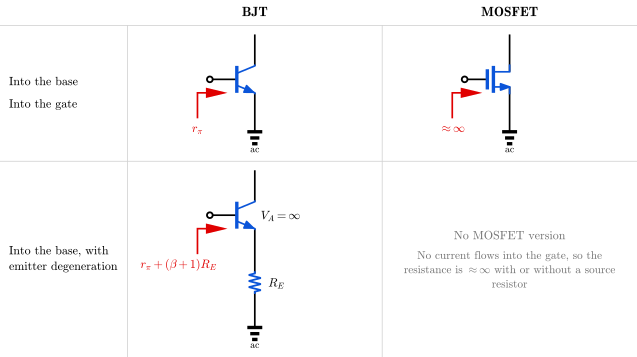

In [9]:
# HIDE/SHOW
def into_base(c):
    """Into the base | Into the gate"""
    t = c.transistor('n', (0, 0), 'cd')
    c.w(t.cd, (0, -20))
    c.w(t.es, (0, 100)); c.ac((0, 100))
    p = (t.bg[0] - 20, 40)
    c.w(t.bg, p); c.port(p, None); c.look(p, 'r', 'd', c.pick(r'$r_\pi$', r'$\approx\infty$'))


def into_base_degenerated(c):
    """Into the base, with emitter degeneration | -"""
    t = c.transistor('n', (0, 0), 'cd'); t.note(t.ideal)
    c.w(t.cd, (0, -20))
    c.w(t.es, (0, 100)); c.w(c.res((0, 100), 'R_' + t.pin('es')), (0, 180)); c.ac((0, 180))
    p = (t.bg[0] - 20, 40)
    c.w(t.bg, p); c.port(p, None); c.look(p, 'r', 'd', r'$r_\pi+(\beta+1)R_E$')

show(into_base, into_base_degenerated, notes=[
    '',
    ('',
     r'No current flows into the gate, so the resistance is $\approx\infty$ with or without a source resistor')])

#### Looking into the Collector or Drain

The base or gate is at ac ground. The emitter or source is at ac ground, directly or through a resistor.

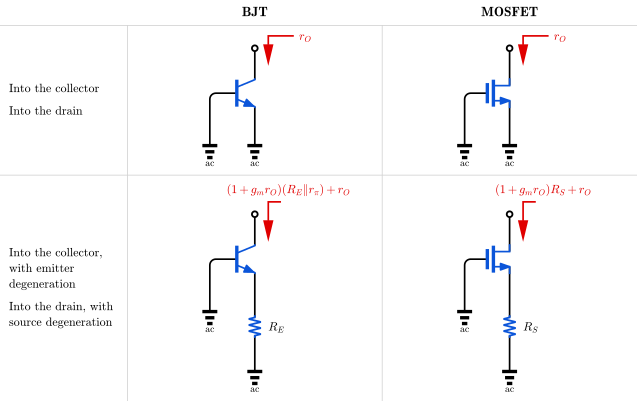

In [10]:
# HIDE/SHOW
def into_collector(c):
    """Into the collector | Into the drain"""
    t = c.transistor('n', (0, 0), 'cd')
    c.w(t.bg, (-60, 40), (-60, 100)); c.ac((-60, 100))
    c.w(t.es, (0, 100)); c.ac((0, 100))
    p = (0, -20)
    c.w(t.cd, p); c.port(p, None); c.look(p, 'd', 'r', '$r_O$')


def into_collector_degenerated(c):
    """Into the collector, with emitter degeneration | Into the drain, with source degeneration"""
    t = c.transistor('n', (0, 0), 'cd')
    c.w(t.bg, (-60, 40), (-60, 100)); c.ac((-60, 100))
    c.w(t.es, (0, 100)); c.w(c.res((0, 100), 'R_' + t.pin('es')), (0, 180)); c.ac((0, 180))
    p = (0, -20)
    c.w(t.cd, p); c.port(p, None)
    c.look(p, 'd', 'r', c.pick(r'$(1+g_mr_O)(R_E\|r_\pi)+r_O$', r'$(1+g_mr_O)R_S+r_O$'), form='long')

show(into_collector, into_collector_degenerated, notes=[
    '',
    ''])

#### Looking into the Emitter or Source

The collector or drain is tied to a load, drawn as a box. The base or gate is at ac ground, directly or through a resistor. Both results hold for $V_A=\infty$ or $\lambda=0$.

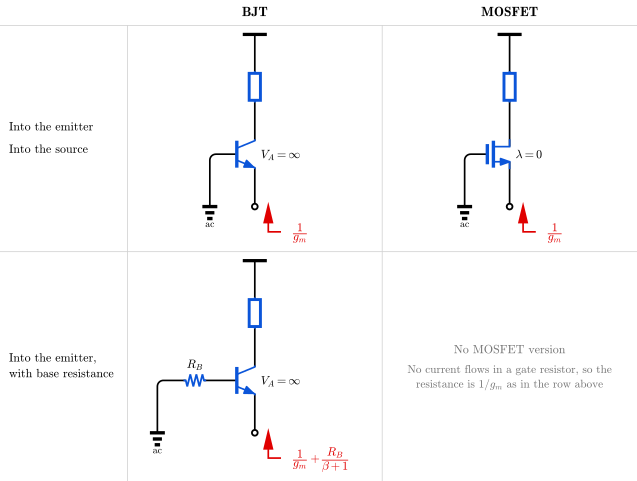

In [11]:
# HIDE/SHOW
def into_emitter(c):
    """Into the emitter | Into the source"""
    t = c.transistor('n', (0, 0), 'cd'); t.note(t.ideal)
    c.supply((0, -110), side=None); c.w((0, -110), (0, -80)); c.w(c.load((0, -80)), t.cd)
    c.w(t.bg, (-60, 40), (-60, 100)); c.ac((-60, 100))
    p = (0, 110)
    c.w(t.es, p); c.port(p, None); c.look(p, 'u', 'r', r'$\dfrac{1}{g_m}$', form='low')


def into_emitter_base_resistance(c):
    """Into the emitter, with base resistance | -"""
    t = c.transistor('n', (0, 0), 'cd'); t.note(t.ideal)
    c.supply((0, -110), side=None); c.w((0, -110), (0, -80)); c.w(c.load((0, -80)), t.cd)
    c.w(t.bg, (t.bg[0] - 10, 40))
    left = c.res((t.bg[0] - 10, 40), 'R_' + t.pin('bg'), to='left', side='u')
    c.w(left, (left[0] - 20, 40), (left[0] - 20, 100)); c.ac((left[0] - 20, 100))
    p = (0, 110)
    c.w(t.es, p); c.port(p, None); c.look(p, 'u', 'r', r'$\dfrac{1}{g_m}+\dfrac{R_B}{\beta+1}$', form='low')

show(into_emitter, into_emitter_base_resistance, notes=[
    '',
    ('',
     'No current flows in a gate resistor, so the resistance is $1/g_m$ as in the row above')])

### Voltage Gain Equations

The small-signal voltage gain $A_v=v_\mathrm{out}/v_\mathrm{in}$ of the three amplifier connections, in eight stages: four for each technology, with the gain under each stage. $V_A=\infty$ or $\lambda=0$ beside a transistor is the condition under which the gain holds.

#### Common-Emitter and Common-Source Stages

The input drives the base or gate, and the output is taken at the collector or drain. A resistor in the emitter or source degenerates the stage; that gain holds for $V_A=\infty$ or $\lambda=0$.

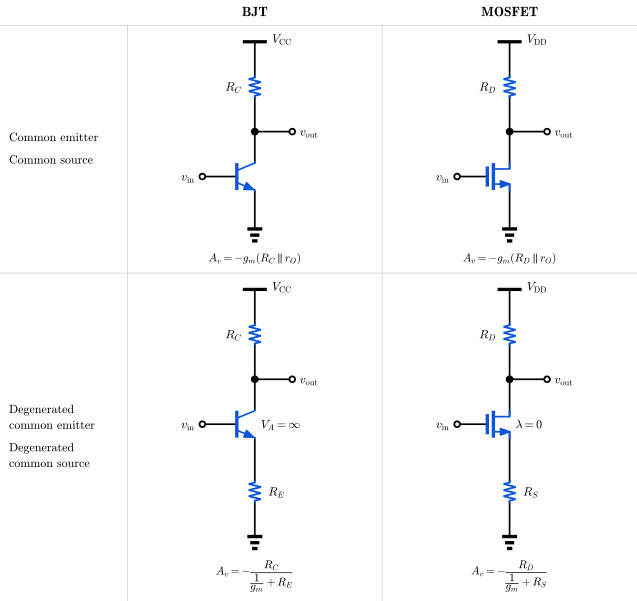

In [12]:
# HIDE/SHOW
def gain_common_emitter(c):
    """Common emitter | Common source"""
    t = c.transistor('n', (0, 0), 'cd')
    C = t.pin('cd')
    c.supply((0, -130)); c.w((0, -130), (0, -110))
    out = (0, -20)
    c.w(c.res((0, -110), 'R_' + C, side='l'), t.cd); c.dot(out)
    c.w(out, (50, -20)); c.port((50, -20), 'v_out', 'r')
    c.w(t.es, (0, 100)); c.gnd((0, 100))
    c.w(t.bg, (t.bg[0] - 30, 40)); c.port((t.bg[0] - 30, 40), 'v_in', 'l')


def gain_degenerated(c):
    """Degenerated common emitter | Degenerated common source"""
    t = c.transistor('n', (0, 0), 'cd'); t.note(t.ideal)
    C, E = t.pin('cd'), t.pin('es')
    c.supply((0, -130)); c.w((0, -130), (0, -110))
    out = (0, -20)
    c.w(c.res((0, -110), 'R_' + C, side='l'), t.cd); c.dot(out)
    c.w(out, (50, -20)); c.port((50, -20), 'v_out', 'r')
    c.w(t.es, (0, 100)); c.w(c.res((0, 100), 'R_' + E), (0, 180)); c.gnd((0, 180))
    c.w(t.bg, (t.bg[0] - 30, 40)); c.port((t.bg[0] - 30, 40), 'v_in', 'l')

show(gain_common_emitter, gain_degenerated, notes=[
    (r'$A_v=-g_m(R_C\parallel r_O)$',
     r'$A_v=-g_m(R_D\parallel r_O)$'),
    (r'$A_v=-\dfrac{R_C}{\dfrac{1}{g_m}+R_E}$',
     r'$A_v=-\dfrac{R_D}{\dfrac{1}{g_m}+R_S}$')])

#### Common-Base or Common-Gate Stage and Follower

In the common-base or common-gate stage the input drives the emitter or source through a resistor, and the base or gate is held at $V_b$. In the follower the output is taken at the emitter or source.

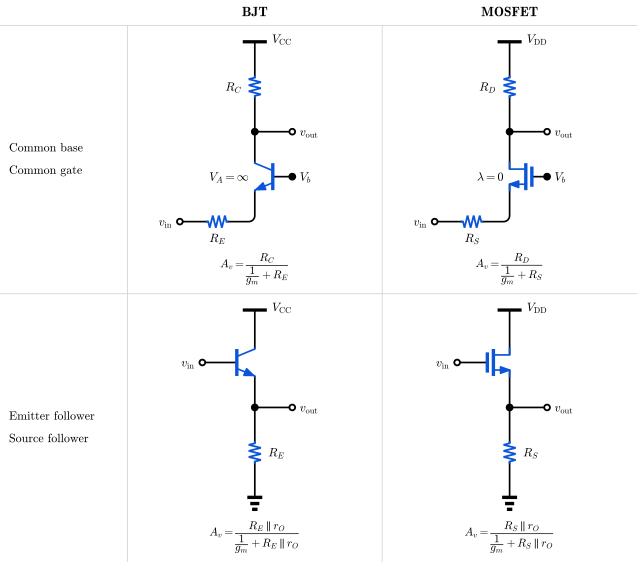

In [13]:
# HIDE/SHOW
def gain_common_base(c):
    """Common base | Common gate"""
    t = c.transistor('n', (0, 0), 'cd', side='right'); t.note(t.ideal)
    C, E = t.pin('cd'), t.pin('es')
    c.supply((0, -130)); c.w((0, -130), (0, -110))
    out = (0, -20)
    c.w(c.res((0, -110), 'R_' + C, side='l'), t.cd); c.dot(out)
    c.w(out, (50, -20)); c.port((50, -20), 'v_out', 'r')
    c.w(t.bg, (t.bg[0] + 10, 40)); c.port((t.bg[0] + 10, 40), 'V_b', 'r', solid=True)
    c.w(t.es, (0, 100), (-20, 100))
    left = c.res((-20, 100), 'R_' + E, to='left')
    c.w(left, (left[0] - 20, 100)); c.port((left[0] - 20, 100), 'v_in', 'l')


def gain_follower(c):
    """Emitter follower | Source follower"""
    t = c.transistor('n', (0, 0), 'cd')
    E = t.pin('es')
    c.supply((0, -20)); c.w((0, -20), t.cd)
    out = (0, 100)
    c.w(t.es, (0, 130)); c.dot(out)
    c.w(out, (50, 100)); c.port((50, 100), 'v_out', 'r')
    c.w(c.res((0, 130), 'R_' + E), (0, 210)); c.gnd((0, 210))
    c.w(t.bg, (t.bg[0] - 30, 40)); c.port((t.bg[0] - 30, 40), 'v_in', 'l')

show(gain_common_base, gain_follower, notes=[
    (r'$A_v=\dfrac{R_C}{\dfrac{1}{g_m}+R_E}$',
     r'$A_v=\dfrac{R_D}{\dfrac{1}{g_m}+R_S}$'),
    (r'$A_v=\dfrac{R_E\parallel r_O}{\dfrac{1}{g_m}+R_E\parallel r_O}$',
     r'$A_v=\dfrac{R_S\parallel r_O}{\dfrac{1}{g_m}+R_S\parallel r_O}$')])

## Connections of Two Transistors

### Bias Circuits

Circuits that set a dc voltage or a dc current.

#### Voltage Divider and PTAT Generator

Two devices of the same type are stacked and carry the same current. In the divider each device is diode-connected. In the PTAT generator both bases or gates go to the top of the stack.

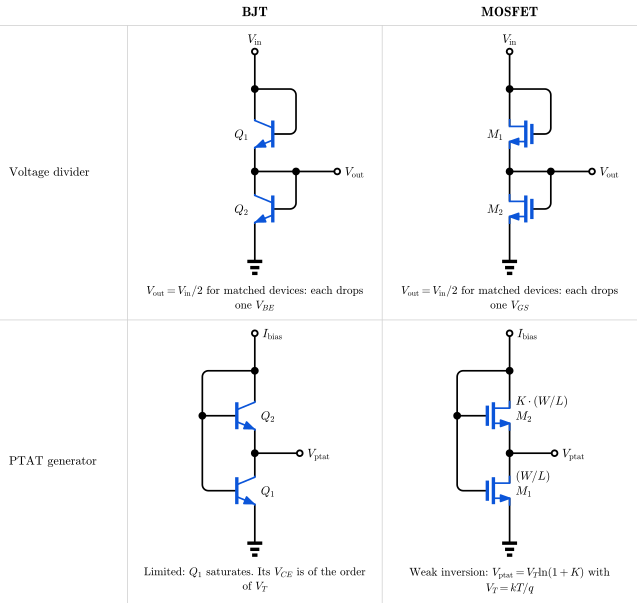

In [14]:
# HIDE/SHOW
def voltage_divider(c):
    """Voltage divider"""
    (t1, t2), (j,) = c.chain([('n', 1), ('n', 2)], 0, 0, side='right')
    top = (0, -20)
    c.port((0, -70), IN, 't'); c.w((0, -70), top, t1.cd); c.dot(top)
    g = (0, t2.es[1] + 20); c.gnd(g); c.w(t2.es, g)
    xt = 55
    c.w(t1.bg, (xt, t1.bg[1]), (xt, top[1]), top)
    c.w(t2.bg, (xt, t2.bg[1]), (xt, j[1]), j); c.dot((xt, j[1])); c.dot(j)
    c.w((xt, j[1]), (xt + 55, j[1])); c.port((xt + 55, j[1]), OUT, 'r')


def ptat_generator(c):
    """PTAT generator"""
    (t2, t1), (j,) = c.chain([('n', 2), ('n', 1)], 0, 0)
    t2.size('K·(W/L)'); t1.size('(W/L)')
    g = (0, t1.es[1] + 20); c.gnd(g); c.w(t1.es, g)
    top = (0, -20); c.w(t2.cd, top); c.dot(top); c.w(top, (0, -70)); c.port((0, -70), 'I_bias', 'r')
    xg = -70
    c.w(top, (xg, top[1]), (xg, t1.bg[1])); c.w(t2.bg, (xg, t2.bg[1])); c.w(t1.bg, (xg, t1.bg[1])); c.dot((xg, t2.bg[1]))
    c.dot(j); c.w(j, (60, j[1])); c.port((60, j[1]), 'V_ptat', 'r')

show(voltage_divider, ptat_generator, notes=[
    (r'$V_\mathrm{out}=V_\mathrm{in}/2$ for matched devices: each drops one $V_{BE}$',
     r'$V_\mathrm{out}=V_\mathrm{in}/2$ for matched devices: each drops one $V_{GS}$'),
    ('Limited: $Q_1$ saturates. Its $V_{CE}$ is of the order of $V_T$',
     r'Weak inversion: $V_\mathrm{ptat}=V_T\ln(1+K)$ with $V_T=kT/q$')])

#### Bias Generator and Tie Cell

A p-type device sits on the supply side and an n-type device on the ground side. One of the two is diode-connected and sets the level.

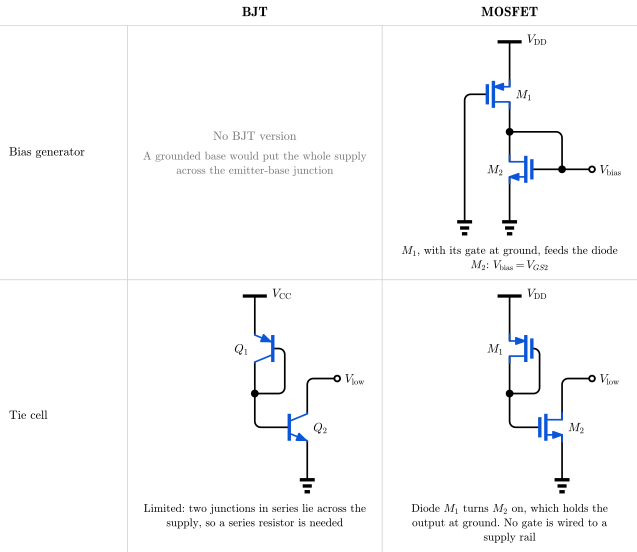

In [15]:
# HIDE/SHOW
def bias_generator(c):
    """- | Bias generator"""
    (t1, t2), (j,) = c.chain([('p', 1), ('n', 2, {'side': 'right'})], 0, 0)
    c.supply((0, -20)); c.w((0, -20), t1.es)
    g = (0, t2.es[1] + 20); c.gnd(g); c.w(t2.es, g)
    xg = -60
    c.w(t1.bg, (xg, t1.bg[1]), (xg, t2.es[1] + 20)); c.gnd((xg, t2.es[1] + 20))
    c.w(j, (70, j[1]), (70, t2.bg[1])); c.dot(j); c.dot((70, t2.bg[1]))
    c.w((70, t2.bg[1]), t2.bg); c.w((70, t2.bg[1]), (110, t2.bg[1])); c.port((110, t2.bg[1]), 'V_bias', 'r')


def tie_cell(c):
    """Tie cell"""
    p = c.transistor('p', (0, 0), 'es', side='right', name=1)
    c.supply((0, -20)); c.w((0, -20), p.es)
    n = c.transistor('n', (30, 145), 'bg', name=2)
    c.w(n.bg, (0, n.bg[1]), p.cd)
    tap = (0, 100)
    c.w(p.bg, (p.bg[0], 100), tap); c.dot(tap)
    c.w(n.cd, (n.cd[0], p.cd[1]), (n.cd[0] + 40, p.cd[1])); c.port((n.cd[0] + 40, p.cd[1]), 'V_low', 'r')
    g = (n.es[0], n.es[1] + 20); c.gnd(g); c.w(n.es, g)
    c.center(0)                                             # aligned on the route from the supply

show(bias_generator, tie_cell, notes=[
    ('A grounded base would put the whole supply across the emitter-base junction',
     r'$M_1$, with its gate at ground, feeds the diode $M_2$: $V_\mathrm{bias}=V_{GS2}$'),
    ('Limited: two junctions in series lie across the supply, so a series resistor is needed',
     'Diode $M_1$ turns $M_2$ on, which holds the output at ground. No gate is wired to a supply rail')])

#### Current Mirror and Current Divider

Both bases or gates are tied together, so the device sizes set a current ratio. The mirror copies a current. The divider splits one.

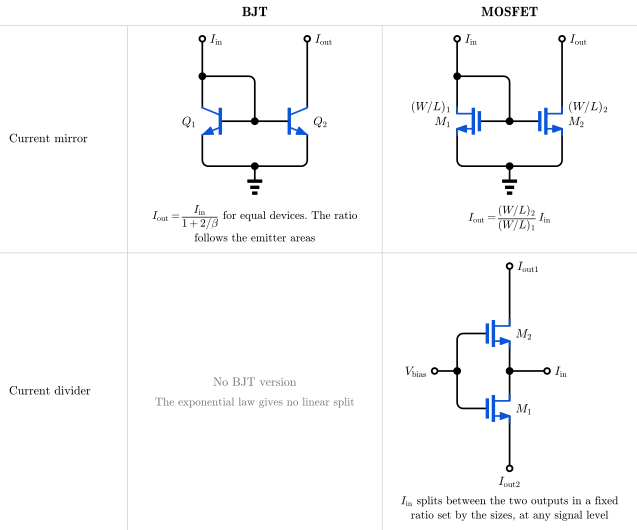

In [16]:
# HIDE/SHOW
def current_mirror(c):
    """Current mirror"""
    t1 = c.transistor('n', (0, 0), 'cd', side='right', name=1, lbl='l')
    t2 = c.transistor('n', (140, 0), 'cd', name=2, lbl='r')
    t1.size('(W/L)_1'); t2.size('(W/L)_2')
    top = (0, -20)
    c.w(t1.cd, top); c.dot(top); c.w(top, (0, -70)); c.port((0, -70), 'I_in', 'r')
    c.w(t2.cd, (140, -70)); c.port((140, -70), 'I_out', 'r')
    gy = t1.bg[1]
    c.w(t1.bg, t2.bg); mx = (t1.bg[0] + t2.bg[0]) / 2
    c.dot((mx, gy)); c.w((mx, gy), (mx, top[1]), top)
    yb = t1.es[1] + 20
    c.w(t1.es, (0, yb), (140, yb), t2.es)
    c.dot((70, yb)); c.w((70, yb), (70, yb + 10)); c.gnd((70, yb + 10))


def current_divider(c):
    """- | Current divider"""
    (t2, t1), (j,) = c.chain([('n', 2), ('n', 1)], 0, 0)
    xin = -70
    c.bus([t2, t1], xin)
    yg = j[1]; c.dot((xin, yg)); c.w((xin, yg), (xin - 30, yg)); c.port((xin - 30, yg), 'V_bias', 'l')
    c.w(t2.cd, (0, -50)); c.port((0, -50), 'I_out1', 'r')
    c.w(t1.es, (0, t1.es[1] + 40)); c.port((0, t1.es[1] + 40), 'I_out2', 'b')
    c.dot(j); c.w(j, (50, j[1])); c.port((50, j[1]), 'I_in', 'r')

show(current_mirror, current_divider, notes=[
    (r'$I_\mathrm{out}=\dfrac{I_\mathrm{in}}{1+2/\beta}$ for equal devices. The ratio follows the emitter areas',
     r'$I_\mathrm{out}=\dfrac{(W/L)_2}{(W/L)_1}\,I_\mathrm{in}$'),
    ('The exponential law gives no linear split',
     r'$I_\mathrm{in}$ splits between the two outputs in a fixed ratio set by the sizes, at any signal level')])

### Gain Stages

One device amplifies. The other is its load or its degeneration, or it amplifies as well.

#### Active Load and Inverter

An n-type and a p-type device are stacked between the rails, with the output at their junction. With the upper base or gate at a fixed bias, the upper device is a current-source load. With both inputs tied together, both devices amplify.

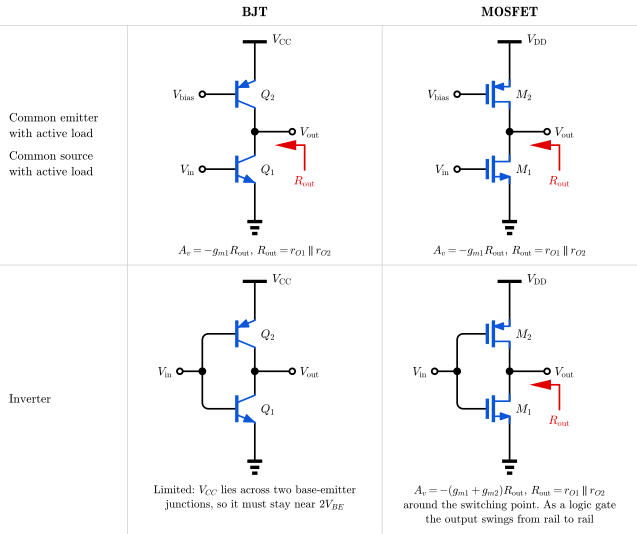

In [17]:
# HIDE/SHOW
def active_load(c):
    """Common emitter with active load | Common source with active load"""
    (t2, t1), (j,) = c.chain([('p', 2), ('n', 1)], 0, 0)
    c.supply((0, -20)); c.w((0, -20), t2.es)
    g = (0, t1.es[1] + 20); c.gnd(g); c.w(t1.es, g)
    c.w(t2.bg, (t2.bg[0] - 30, t2.bg[1])); c.port((t2.bg[0] - 30, t2.bg[1]), 'V_bias', 'l')
    c.w(t1.bg, (t1.bg[0] - 30, t1.bg[1])); c.port((t1.bg[0] - 30, t1.bg[1]), IN, 'l')
    c.dot(j); c.w(j, (50, j[1])); c.port((50, j[1]), OUT, 'r'); c.look((50, j[1]), 'l', 'd', 'R_out')


def inverter(c):
    """Inverter"""
    (p, n), (j,) = c.chain([('p', 2), ('n', 1)], 0, 0)
    c.supply((0, -20)); c.w((0, -20), p.top)
    g = (0, n.es[1] + 20); c.gnd(g); c.w(n.es, g)
    xin = -70
    c.bus([p, n], xin)
    c.dot((xin, j[1])); c.w((xin, j[1]), (xin - 30, j[1])); c.port((xin - 30, j[1]), IN, 'l')
    c.dot(j); c.w(j, (50, j[1])); c.port((50, j[1]), OUT, 'r')
    if c.device is MOSFET:                                  # the BJT version has no gain to speak of
        c.look((50, j[1]), 'l', 'd', 'R_out')

show(active_load, inverter, notes=[
    r'$A_v=-g_{m1}R_\mathrm{out}$, $R_\mathrm{out}=r_{O1}\parallel r_{O2}$',
    ('Limited: $V_{CC}$ lies across two base-emitter junctions, so it must stay near $2V_{BE}$',
     r'$A_v=-(g_{m1}+g_{m2})R_\mathrm{out}$, $R_\mathrm{out}=r_{O1}\parallel r_{O2}$ around the switching point. As a logic gate the output swings from rail to rail')])

#### Stacked and Folded Diode Loads

The load is a diode-connected device of the same type as the amplifying device. It sits on top of that device, or beside it with its own share of a bias current.

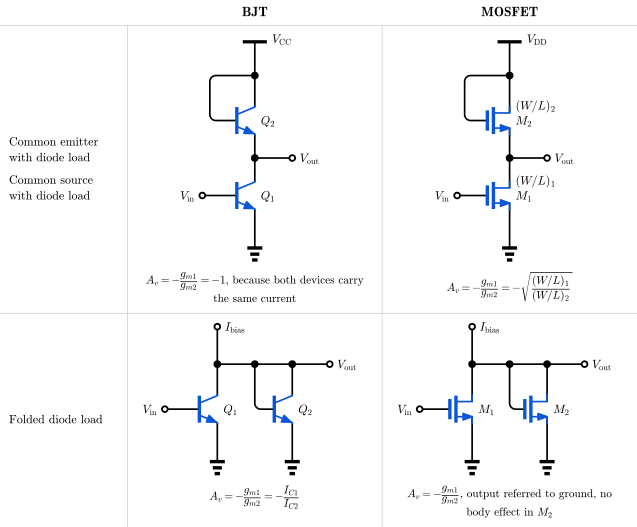

In [18]:
# HIDE/SHOW
def diode_load(c):
    """Common emitter with diode load | Common source with diode load"""
    (t2, t1), (j,) = c.chain([('n', 2), ('n', 1)], 0, 0)
    t2.size('(W/L)_2'); t1.size('(W/L)_1')
    top = (0, -20); c.supply((0, -55)); c.w((0, -55), top, t2.cd); c.dot(top)
    c.w(t2.bg, (t2.bg[0] - 20, t2.bg[1]), (t2.bg[0] - 20, top[1]), top)
    g = (0, t1.es[1] + 20); c.gnd(g); c.w(t1.es, g)
    c.w(t1.bg, (t1.bg[0] - 30, t1.bg[1])); c.port((t1.bg[0] - 30, t1.bg[1]), IN, 'l')
    c.dot(j); c.w(j, (50, j[1])); c.port((50, j[1]), OUT, 'r')


def folded_diode_load(c):
    """Folded diode load"""
    t1 = c.transistor('n', (0, 0), 'cd', name=1)
    t2 = c.transistor('n', (100, 0), 'cd', name=2)
    for t in (t1, t2):
        g = (t.es[0], t.es[1] + 20); c.gnd(g); c.w(t.es, g)
    c.w(t1.bg, (t1.bg[0] - 30, t1.bg[1])); c.port((t1.bg[0] - 30, t1.bg[1]), IN, 'l')
    node = (0, -20)
    c.w(t1.cd, (0, -70)); c.dot(node); c.port((0, -70), 'I_bias', 'r')
    c.w(node, (150, -20)); c.port((150, -20), OUT, 'r')
    c.w(t2.cd, (100, -20)); c.dot((100, -20))                         # the second transistor is diode-connected
    c.w((50, -20), (50, t2.bg[1]), t2.bg); c.dot((50, -20))

show(diode_load, folded_diode_load, notes=[
    (r'$A_v=-\dfrac{g_{m1}}{g_{m2}}=-1$, because both devices carry the same current',
     r'$A_v=-\dfrac{g_{m1}}{g_{m2}}=-\sqrt{\dfrac{(W/L)_1}{(W/L)_2}}$'),
    (r'$A_v=-\dfrac{g_{m1}}{g_{m2}}=-\dfrac{I_{C1}}{I_{C2}}$',
     r'$A_v=-\dfrac{g_{m1}}{g_{m2}}$, output referred to ground, no body effect in $M_2$')])

#### Fixed and Tunable Degeneration

The lower device takes the place of a resistor in the source of the upper one. Its gate is driven by the input, or by a separate bias.

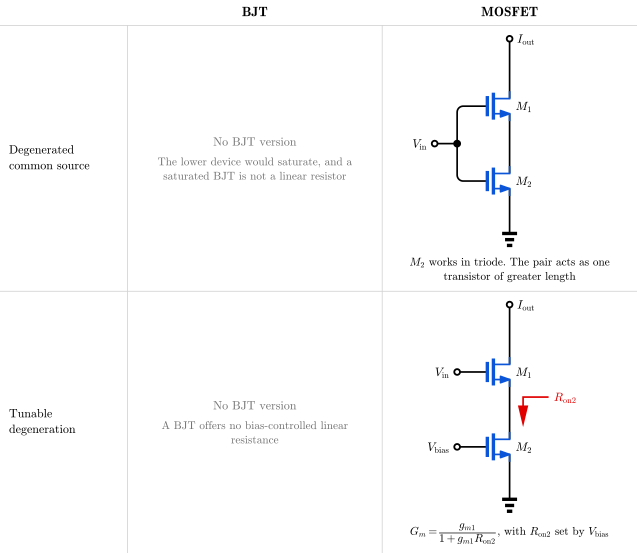

In [19]:
# HIDE/SHOW
def degeneration(c):
    """- | Degenerated common source"""
    (t1, t2), (j,) = c.chain([('n', 1), ('n', 2)], 0, 0)
    g = (0, t2.es[1] + 20); c.gnd(g); c.w(t2.es, g)
    c.w(t1.cd, (0, -50)); c.port((0, -50), 'I_out', 'r')
    xin = -70
    c.bus([t1, t2], xin)
    yi = j[1]; c.dot((xin, yi)); c.w((xin, yi), (xin - 30, yi)); c.port((xin - 30, yi), IN, 'l')


def tunable_degeneration(c):
    """- | Tunable degeneration"""
    (t1, t2), (j,) = c.chain([('n', 1), ('n', 2)], 0, 0)
    g = (0, t2.es[1] + 20); c.gnd(g); c.w(t2.es, g)
    c.w(t1.cd, (0, -50)); c.port((0, -50), 'I_out', 'r')
    c.w(t1.bg, (t1.bg[0] - 30, t1.bg[1])); c.port((t1.bg[0] - 30, t1.bg[1]), IN, 'l')
    c.w(t2.bg, (t2.bg[0] - 30, t2.bg[1])); c.port((t2.bg[0] - 30, t2.bg[1]), 'V_bias', 'l')
    c.look(j, 'd', 'r', 'R_on2')

show(degeneration, tunable_degeneration, notes=[
    ('The lower device would saturate, and a saturated BJT is not a linear resistor',
     '$M_2$ works in triode. The pair acts as one transistor of greater length'),
    ('A BJT offers no bias-controlled linear resistance',
     r'$G_m=\dfrac{g_{m1}}{1+g_{m1}R_\mathrm{on2}}$, with $R_\mathrm{on2}$ set by $V_\mathrm{bias}$')])

### Buffers

The signal is passed on, as a voltage or as a current, at a different impedance level.

#### Class-A and Push-Pull Followers

A follower passes a voltage. Its partner is a current source, or a complementary follower that takes over for the other signal polarity.

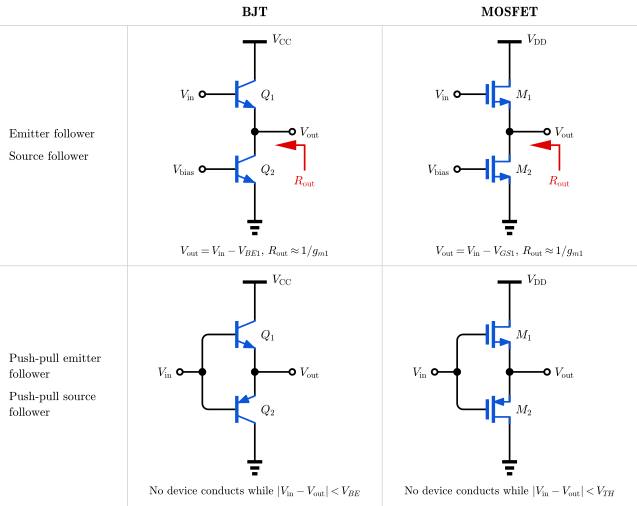

In [20]:
# HIDE/SHOW
def follower(c):
    """Emitter follower | Source follower"""
    (t1, t2), (j,) = c.chain([('n', 1), ('n', 2)], 0, 0)
    c.supply((0, -20)); c.w((0, -20), t1.cd)
    g = (0, t2.es[1] + 20); c.gnd(g); c.w(t2.es, g)
    c.w(t1.bg, (t1.bg[0] - 30, t1.bg[1])); c.port((t1.bg[0] - 30, t1.bg[1]), IN, 'l')
    c.w(t2.bg, (t2.bg[0] - 30, t2.bg[1])); c.port((t2.bg[0] - 30, t2.bg[1]), 'V_bias', 'l')
    c.dot(j); c.w(j, (50, j[1])); c.port((50, j[1]), OUT, 'r'); c.look((50, j[1]), 'l', 'd', 'R_out')


def push_pull(c):
    """Push-pull emitter follower | Push-pull source follower"""
    (t1, t2), (j,) = c.chain([('n', 1), ('p', 2)], 0, 0)
    c.supply((0, -20)); c.w((0, -20), t1.cd)
    g = (0, t2.cd[1] + 20); c.gnd(g); c.w(t2.cd, g)
    xin = -70
    c.bus([t1, t2], xin)
    yi = j[1]; c.dot((xin, yi)); c.w((xin, yi), (xin - 30, yi)); c.port((xin - 30, yi), IN, 'l')
    c.dot(j); c.w(j, (50, j[1])); c.port((50, j[1]), OUT, 'r')

show(follower, push_pull, notes=[
    (r'$V_\mathrm{out}=V_\mathrm{in}-V_{BE1}$, $R_\mathrm{out}\approx1/g_{m1}$',
     r'$V_\mathrm{out}=V_\mathrm{in}-V_{GS1}$, $R_\mathrm{out}\approx1/g_{m1}$'),
    (r'No device conducts while $|V_\mathrm{in}-V_\mathrm{out}|<V_{BE}$',
     r'No device conducts while $|V_\mathrm{in}-V_\mathrm{out}|<V_{TH}$')])

#### Single and Stacked Current Buffers

A current buffer passes a current. Its partner is the current source that biases it, or a second buffer on top.

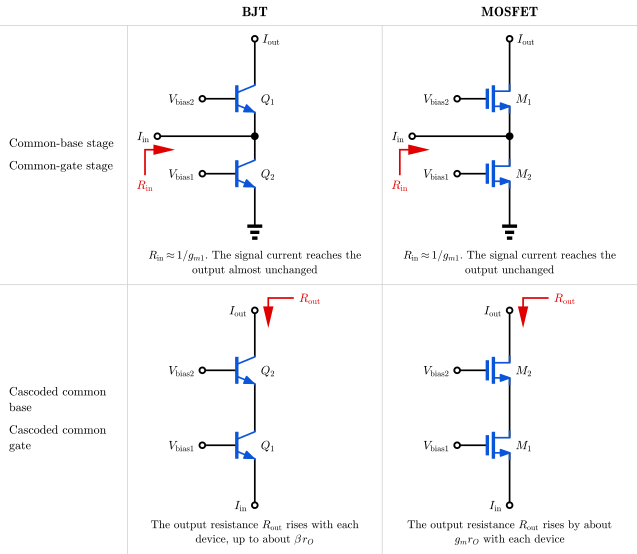

In [21]:
# HIDE/SHOW
def buffer_stage(c):
    """Common-base stage | Common-gate stage"""
    (t1, t2), (j,) = c.chain([('n', 1), ('n', 2)], 0, 0)
    g = (0, t2.es[1] + 20); c.gnd(g); c.w(t2.es, g)
    c.w(t1.bg, (t1.bg[0] - 30, t1.bg[1])); c.port((t1.bg[0] - 30, t1.bg[1]), 'V_bias2', 'l')
    c.w(t2.bg, (t2.bg[0] - 30, t2.bg[1])); c.port((t2.bg[0] - 30, t2.bg[1]), 'V_bias1', 'l')
    xl = t1.bg[0] - 90
    c.dot(j); c.w(j, (xl, j[1])); c.port((xl, j[1]), 'I_in', 'l'); c.look((xl, j[1]), 'r', 'd', 'R_in')
    c.w(t1.cd, (0, -40)); c.port((0, -40), 'I_out', 'r')


def stacked_buffers(c):
    """Cascoded common base | Cascoded common gate"""
    (t2, t1), (j,) = c.chain([('n', 2), ('n', 1)], 0, 0)
    c.w(t1.bg, (t1.bg[0] - 30, t1.bg[1])); c.port((t1.bg[0] - 30, t1.bg[1]), 'V_bias1', 'l')
    c.w(t2.bg, (t2.bg[0] - 30, t2.bg[1])); c.port((t2.bg[0] - 30, t2.bg[1]), 'V_bias2', 'l')
    c.w(t2.cd, (0, -40)); c.port((0, -40), 'I_out', 'l'); c.look((0, -40), 'd', 'r', 'R_out')
    c.w(t1.es, (0, t1.es[1] + 40)); c.port((0, t1.es[1] + 40), 'I_in', 'l')

show(buffer_stage, stacked_buffers, notes=[
    (r'$R_\mathrm{in}\approx1/g_{m1}$. The signal current reaches the output almost unchanged',
     r'$R_\mathrm{in}\approx1/g_{m1}$. The signal current reaches the output unchanged'),
    (r'The output resistance $R_\mathrm{out}$ rises with each device, up to about $\beta\,r_O$',
     r'The output resistance $R_\mathrm{out}$ rises by about $g_mr_O$ with each device')])

#### Two Outputs and Two Paths

One input drives the base or gate of one device and the emitter or source of the other at the same time.

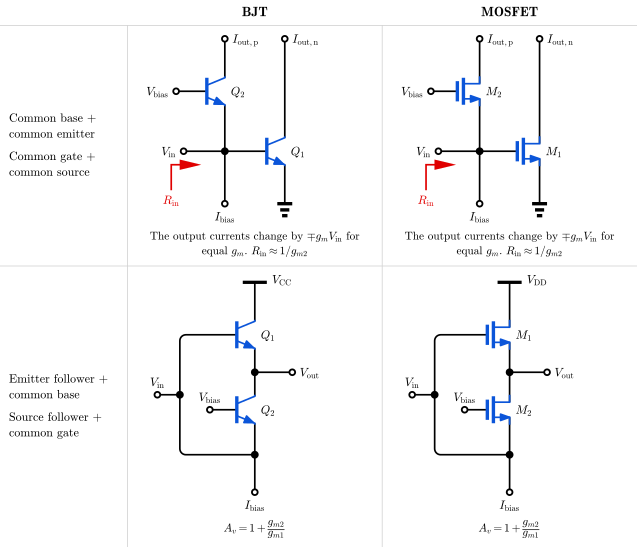

In [22]:
# HIDE/SHOW
def two_outputs(c):
    """Common base + common emitter | Common gate + common source"""
    t1 = c.transistor('n', (0, 0), 'cd', name=1)
    t2 = c.transistor('n', (-80, 0), 'es', name=2)
    yt = -110
    c.w(t1.cd, (0, yt)); c.port((0, yt), 'I_out,n', 'r')
    c.w(t2.cd, (-80, yt)); c.port((-80, yt), 'I_out,p', 'r')
    g = (0, t1.es[1] + 20); c.gnd(g); c.w(t1.es, g)
    c.w(t2.bg, (t2.bg[0] - 25, t2.bg[1])); c.port((t2.bg[0] - 25, t2.bg[1]), 'V_bias', 'l')
    nd = (-80, t1.bg[1])
    c.w(t2.es, nd); c.dot(nd); c.w(nd, t1.bg)
    c.w(nd, (-135, nd[1])); c.port((-135, nd[1]), IN, 'l'); c.look((-135, nd[1]), 'r', 'd', 'R_in')
    c.w(nd, (-80, nd[1] + 70)); c.port((-80, nd[1] + 70), 'I_bias', 'b')


def two_paths(c):
    """Emitter follower + common base | Source follower + common gate"""
    (t1, t2), (j,) = c.chain([('n', 1), ('n', 2)], 0, 0)
    c.supply((0, -20)); c.w((0, -20), t1.cd)
    inp = (0, t2.es[1] + 20); c.w(t2.es, inp); c.dot(inp); c.w(inp, (0, inp[1] + 50)); c.port((0, inp[1] + 50), 'I_bias', 'b')
    c.w(t2.bg, (t2.bg[0] - 20, t2.bg[1])); c.port((t2.bg[0] - 20, t2.bg[1]), 'V_bias', 't', dx=8)
    xl = -100
    c.w(inp, (xl, inp[1]), (xl, t1.bg[1]), t1.bg)
    tap = (xl, (inp[1] + t1.bg[1]) / 2)
    c.dot(tap); c.w(tap, (xl - 30, tap[1])); c.port((xl - 30, tap[1]), IN, 't')
    c.dot(j); c.w(j, (50, j[1])); c.port((50, j[1]), OUT, 'r')

show(two_outputs, two_paths, notes=[
    r'The output currents change by $\mp g_mV_\mathrm{in}$ for equal $g_m$. $R_\mathrm{in}\approx1/g_{m2}$',
    r'$A_v=1+\dfrac{g_{m2}}{g_{m1}}$'])

### Feedback Pairs

Two devices connected in a loop. The cascode and the differential pair are the same pairs before the loop is closed.

#### Cascode and Regulated Cascode

A current buffer on top of an amplifier shields its collector or drain. In the regulated cascode a second device senses the emitter or source of the buffer and drives its base or gate.

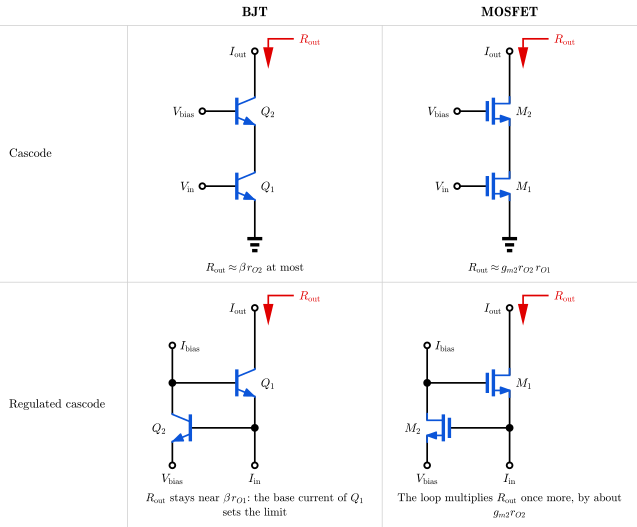

In [23]:
# HIDE/SHOW
def cascode(c):
    """Cascode"""
    (t2, t1), (j,) = c.chain([('n', 2), ('n', 1)], 0, 0)
    g = (0, t1.es[1] + 20); c.gnd(g); c.w(t1.es, g)
    c.w(t1.bg, (t1.bg[0] - 30, t1.bg[1])); c.port((t1.bg[0] - 30, t1.bg[1]), IN, 'l')
    c.w(t2.bg, (t2.bg[0] - 30, t2.bg[1])); c.port((t2.bg[0] - 30, t2.bg[1]), 'V_bias', 'l')
    c.w(t2.cd, (0, -40)); c.port((0, -40), 'I_out', 'l'); c.look((0, -40), 'd', 'r', 'R_out')


def regulated_cascode(c):
    """Regulated cascode"""
    c.center(0)                                             # aligned on the route from I_out to I_in
    t1 = c.transistor('n', (0, 0), 'cd', name=1)
    c.w(t1.cd, (0, -60)); c.port((0, -60), 'I_out', 'l'); c.look((0, -60), 'd', 'r', 'R_out')
    c.w(t1.es, (0, 150)); c.port((0, 150), 'I_in', 'b')
    t2 = c.transistor('n', (-110, 60), 'cd', side='right', name=2, lbl='l')
    gy = t1.bg[1]
    c.w(t2.cd, (-110, gy)); c.dot((-110, gy)); c.w((-110, gy), t1.bg)
    c.w((-110, gy), (-110, -10)); c.port((-110, -10), 'I_bias', 'r')
    c.w(t2.bg, (0, t2.bg[1])); c.dot((0, t2.bg[1]))
    c.w(t2.es, (-110, 150)); c.port((-110, 150), 'V_bias', 'b')

show(cascode, regulated_cascode, notes=[
    (r'$R_\mathrm{out}\approx\beta\,r_{O2}$ at most',
     r'$R_\mathrm{out}\approx g_{m2}r_{O2}\,r_{O1}$'),
    (r'$R_\mathrm{out}$ stays near $\beta\,r_{O1}$: the base current of $Q_1$ sets the limit',
     r'The loop multiplies $R_\mathrm{out}$ once more, by about $g_{m2}r_{O2}$')])

#### Flipped Follower and Active Inductor

Both rows are the same loop: the upper device passes a signal from the lower node up to the bias node, and the lower device amplifies it back down. Driving the upper base or gate gives a follower. Looking into the lower node gives an inductor.

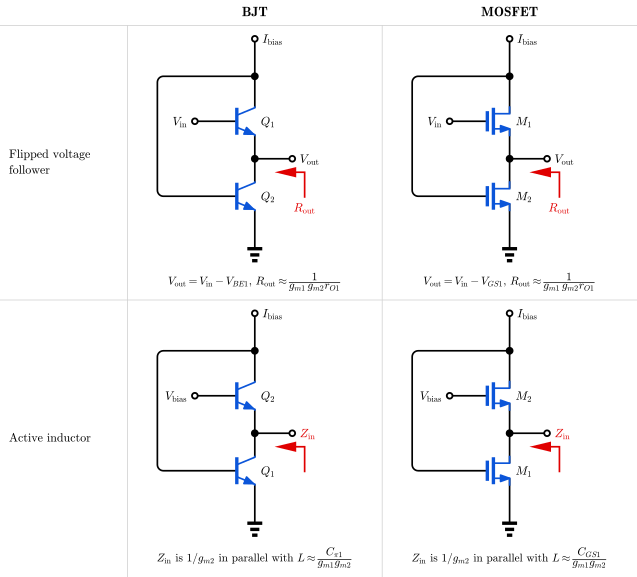

In [24]:
# HIDE/SHOW
def flipped_follower(c):
    """Flipped voltage follower"""
    (t1, t2), (j,) = c.chain([('n', 1), ('n', 2)], 0, 0)
    g = (0, t2.es[1] + 20); c.gnd(g); c.w(t2.es, g)
    top = (0, -20); c.w(t1.cd, top); c.dot(top); c.w(top, (0, -70)); c.port((0, -70), 'I_bias', 'r')
    c.w(t1.bg, (t1.bg[0] - 40, t1.bg[1])); c.port((t1.bg[0] - 40, t1.bg[1]), IN, 'l')
    c.dot(j); c.w(j, (50, j[1])); c.port((50, j[1]), OUT, 'r'); c.look((50, j[1]), 'l', 'd', 'R_out')
    xb = -130
    c.w(top, (xb, top[1]), (xb, t2.bg[1]), t2.bg)


def active_inductor(c):
    """Active inductor"""
    (t2, t1), (j,) = c.chain([('n', 2), ('n', 1)], 0, 0)
    g = (0, t1.es[1] + 20); c.gnd(g); c.w(t1.es, g)
    top = (0, -20); c.w(t2.cd, top); c.dot(top); c.w(top, (0, -70)); c.port((0, -70), 'I_bias', 'r')
    c.w(t2.bg, (t2.bg[0] - 40, t2.bg[1])); c.port((t2.bg[0] - 40, t2.bg[1]), 'V_bias', 'l')
    c.dot(j); c.w(j, (50, j[1])); c.port((50, j[1]), 'Z_in', 'r', color=RED); c.look((50, j[1]), 'l', 'd')
    xb = -130
    c.w(top, (xb, top[1]), (xb, t1.bg[1]), t1.bg)

show(flipped_follower, active_inductor, notes=[
    (r'$V_\mathrm{out}=V_\mathrm{in}-V_{BE1}$, $R_\mathrm{out}\approx\dfrac{1}{g_{m1}\,g_{m2}r_{O1}}$',
     r'$V_\mathrm{out}=V_\mathrm{in}-V_{GS1}$, $R_\mathrm{out}\approx\dfrac{1}{g_{m1}\,g_{m2}r_{O1}}$'),
    (r'$Z_\mathrm{in}$ is $1/g_{m2}$ in parallel with $L\approx\dfrac{C_{\pi1}}{g_{m1}g_{m2}}$',
     r'$Z_\mathrm{in}$ is $1/g_{m2}$ in parallel with $L\approx\dfrac{C_{GS1}}{g_{m1}g_{m2}}$')])

#### Differential and Cross-Coupled Pairs

Two matched devices share a tail current. Connecting each base or gate to the opposite collector or drain turns the amplifier into a negative resistance.

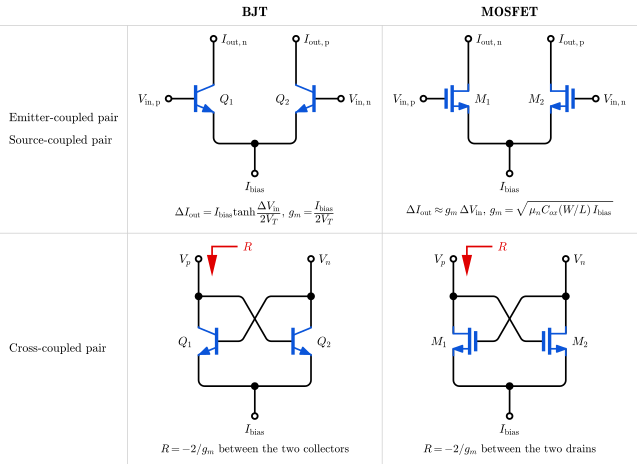

In [25]:
# HIDE/SHOW
def differential_pair(c):
    """Emitter-coupled pair | Source-coupled pair"""
    t1 = c.transistor('n', (0, 0), 'cd', name=1)
    t2 = c.transistor('n', (110, 0), 'cd', side='right', name=2)
    c.w(t1.bg, (t1.bg[0] - 20, t1.bg[1])); c.port((t1.bg[0] - 20, t1.bg[1]), 'V_in,p', 'l')
    c.w(t2.bg, (t2.bg[0] + 20, t2.bg[1])); c.port((t2.bg[0] + 20, t2.bg[1]), 'V_in,n', 'r')
    c.w(t1.cd, (0, -40)); c.port((0, -40), 'I_out,n', 'r')
    c.w(t2.cd, (110, -40)); c.port((110, -40), 'I_out,p', 'r')
    yb = t1.es[1] + 20
    c.w(t1.es, (0, yb), (110, yb), t2.es); c.dot((55, yb))
    c.w((55, yb), (55, yb + 40)); c.port((55, yb + 40), 'I_bias', 'b')


def cross_coupled_pair(c):
    """Cross-coupled pair"""
    t1 = c.transistor('n', (0, 0), 'cd', side='right', name=1)
    t2 = c.transistor('n', (150, 0), 'cd', name=2)
    a, b = (0, -20), (150, -20)
    c.w(t1.cd, (0, -70)); c.dot(a); c.port((0, -70), 'V_p', 'l'); c.look((0, -70), 'd', 'r', 'R')
    c.w(t2.cd, (150, -70)); c.dot(b); c.port((150, -70), 'V_n', 'r')
    xl, xr = c.cross(75, a[1], t1.bg[1])                    # the two wires cross as an X
    c.w(a, (xl, a[1]), (xr, t2.bg[1]), t2.bg)
    c.w(b, (xr, b[1]), (xl, t1.bg[1]), t1.bg)
    ys = 100
    c.w(t1.es, (0, ys), (150, ys), t2.es); c.dot((75, ys)); c.w((75, ys), (75, ys + 40)); c.port((75, ys + 40), 'I_bias', 'b')

show(differential_pair, cross_coupled_pair, notes=[
    (r'$\Delta I_\mathrm{out}=I_\mathrm{bias}\tanh\dfrac{\Delta V_\mathrm{in}}{2V_T}$, $g_m=\dfrac{I_\mathrm{bias}}{2V_T}$',
     r'$\Delta I_\mathrm{out}\approx g_m\,\Delta V_\mathrm{in}$, $g_m=\sqrt{\mu_nC_{ox}(W/L)\,I_\mathrm{bias}}$'),
    ('$R=-2/g_m$ between the two collectors',
     '$R=-2/g_m$ between the two drains')])

### Circuit Elements

The pair stands in for a two-terminal element: a resistor, a capacitor, a diode or a voltage drop.

#### Controlled and Large Resistors

A MOSFET in the triode region is a resistor between source and drain. One device sets the gate voltage of the other, or two devices in series bias each other close to cutoff.

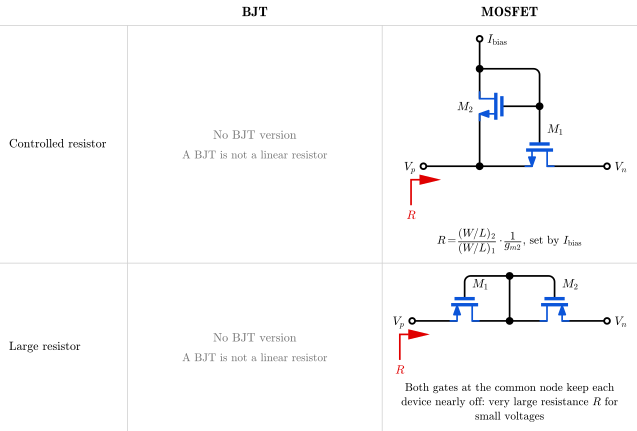

In [26]:
# HIDE/SHOW
def controlled_resistor(c):
    """- | Controlled resistor"""
    t1 = c.transistor('n', (0, 0), 'es', rot=1, name=1)
    tap = (-40, 0)
    c.w(t1.es, tap); c.dot(tap); c.w(tap, (-115, 0)); c.port((-115, 0), 'V_p', 'l'); c.look((-115, 0), 'r', 'd', 'R')
    c.w(t1.cd, (130, 0)); c.port((130, 0), 'V_n', 'r')
    t2 = c.transistor('n', (-40, -40), 'es', side='right', name=2)
    c.w(tap, t2.es)
    gn = (40, -80)
    c.w(t2.bg, gn); c.dot(gn); c.w(gn, t1.bg)
    tp = (-40, -130)
    c.w(t2.cd, tp); c.dot(tp); c.w(tp, (-40, -170)); c.port((-40, -170), 'I_bias', 'r')
    c.w(tp, (40, -130), gn)


def large_resistor(c):
    """- | Large resistor"""
    t1 = c.transistor('p', (0, 0), 'es', side='right', rot=3, name=1)
    t2 = c.transistor('p', (120, 0), 'cd', rot=1, name=2)
    c.w(t1.cd, (100, 0), t2.cd); c.dot((100, 0))
    c.w(t1.es, (-30, 0)); c.port((-30, 0), 'V_p', 'l'); c.look((-30, 0), 'r', 'd', 'R')
    c.w(t2.es, (230, 0)); c.port((230, 0), 'V_n', 'r')
    c.w((100, 0), (100, -60)); c.dot((100, -60))
    c.w(t1.bg, (t1.bg[0], -60), (100, -60))
    c.w(t2.bg, (t2.bg[0], -60), (100, -60))

show(controlled_resistor, large_resistor, notes=[
    ('A BJT is not a linear resistor',
     r'$R=\dfrac{(W/L)_2}{(W/L)_1}\cdot\dfrac{1}{g_{m2}}$, set by $I_\mathrm{bias}$'),
    ('A BJT is not a linear resistor',
     'Both gates at the common node keep each device nearly off: very large resistance $R$ for small voltages')])

#### Varactor and Anti-Parallel Capacitors

The gate of a MOSFET whose source and drain are tied together is one plate of a capacitor.

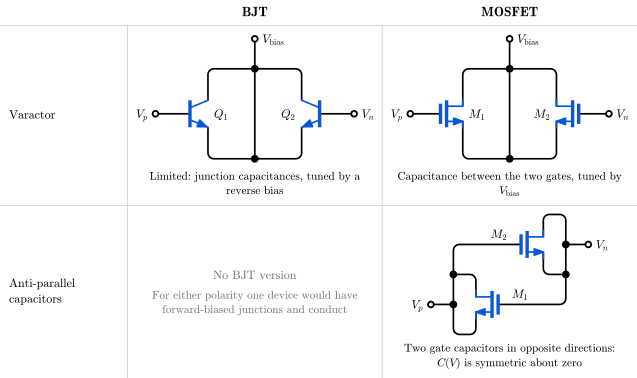

In [27]:
# HIDE/SHOW
def varactor(c):
    """Varactor"""
    t1 = c.transistor('n', (0, 0), 'cd', name=1)
    t2 = c.transistor('n', (125, 0), 'cd', side='right', name=2)
    mx = 62.5
    c.w(t1.cd, (0, -20), (125, -20), t2.cd); c.dot((mx, -20))
    c.w(t1.es, (0, 100), (125, 100), t2.es); c.dot((mx, 100))
    c.w((mx, -20), (mx, 100))
    c.w((mx, -20), (mx, -60)); c.port((mx, -60), 'V_bias', 'r')
    c.w(t1.bg, (t1.bg[0] - 30, t1.bg[1])); c.port((t1.bg[0] - 30, t1.bg[1]), 'V_p', 'l')
    c.w(t2.bg, (t2.bg[0] + 30, t2.bg[1])); c.port((t2.bg[0] + 30, t2.bg[1]), 'V_n', 'r')


def antiparallel_capacitors(c):
    """- | Anti-parallel capacitors"""
    t1 = c.transistor('n', (0, 0), 'cd', side='right')
    t1.name(1, 'r', dy=-14)
    t2 = c.transistor('n', (90, -80), 'cd')
    t2.name(2, 'l', dy=-14)
    xl, xr = -30, 120
    # left terminal: drain and source of the first device, gate of the second
    c.w(t1.cd, (xl, 0)); c.w(t1.es, (xl, 80)); c.w(t2.bg, (xl, t2.bg[1])); c.w((xl, t2.bg[1]), (xl, 80)); c.dot((xl, 0))
    c.dot((xl, 40)); c.w((xl, 40), (xl - 30, 40)); c.port((xl - 30, 40), 'V_p', 'l')
    # right terminal: drain and source of the second device, gate of the first
    c.w(t2.cd, (xr, t2.cd[1])); c.w(t2.es, (xr, t2.es[1])); c.w(t1.bg, (xr, t1.bg[1])); c.w((xr, t1.bg[1]), (xr, t2.cd[1])); c.dot((xr, t2.es[1]))
    c.dot((xr, -40)); c.w((xr, -40), (xr + 30, -40)); c.port((xr + 30, -40), 'V_n', 'r')

show(varactor, antiparallel_capacitors, notes=[
    ('Limited: junction capacitances, tuned by a reverse bias',
     r'Capacitance between the two gates, tuned by $V_\mathrm{bias}$'),
    ('For either polarity one device would have forward-biased junctions and conduct',
     'Two gate capacitors in opposite directions: $C(V)$ is symmetric about zero')])

#### Anti-Parallel and Ultra-Low-Power Diodes

Two diode-connected devices in opposite directions conduct for either polarity. An n-type and a p-type device in series, each controlled from the far terminal, make a diode with very little leakage.

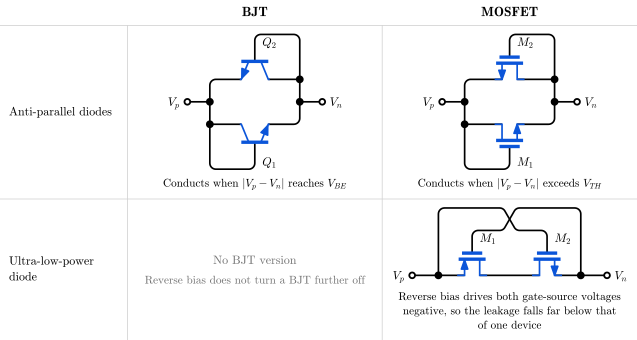

In [28]:
# HIDE/SHOW
def antiparallel_diodes(c):
    """Anti-parallel diodes"""
    t1 = c.transistor('n', (0, 0), 'cd', rot=3, name=1)
    t2 = c.transistor('n', (0, -60), 'es', rot=1, name=2)
    xl, xr = -20, 100
    c.w(t1.cd, (xl, 0), (xl, -60), t2.es); c.dot((xl, -30)); c.w((xl, -30), (xl - 30, -30)); c.port((xl - 30, -30), 'V_p', 'l')
    c.w(t1.es, (xr, 0), (xr, -60), t2.cd); c.dot((xr, -30)); c.w((xr, -30), (xr + 30, -30)); c.port((xr + 30, -30), 'V_n', 'r')
    c.w(t1.bg, (t1.bg[0], t1.bg[1] + 20), (xl, t1.bg[1] + 20), (xl, 0)); c.dot((xl, 0))
    c.w(t2.bg, (t2.bg[0], t2.bg[1] - 20), (xr, t2.bg[1] - 20), (xr, -60)); c.dot((xr, -60))


def low_leakage_diode(c):
    """- | Ultra-low-power diode"""
    t1 = c.transistor('p', (0, 0), 'es', side='right', rot=3, name=1)
    t2 = c.transistor('n', (100, 0), 'cd', side='right', rot=3, name=2)
    c.w(t1.cd, t2.cd)
    a, b = (-5, 0), (t2.es[0] + 5, 0)                        # half-way between the terminal and the device
    c.w(t1.es, (-40, 0)); c.dot(a); c.port((-40, 0), 'V_p', 'l')
    c.w(t2.es, (220, 0)); c.dot(b); c.port((220, 0), 'V_n', 'r')
    y1, y2 = -60, -90
    xl, xr = c.cross(90, y1, y2)                            # the two wires cross as an X
    c.w(t1.bg, (t1.bg[0], y1), (xl, y1), (xr, y2), (b[0], y2), b)
    c.w(t2.bg, (t2.bg[0], y1), (xr, y1), (xl, y2), (a[0], y2), a)

show(antiparallel_diodes, low_leakage_diode, notes=[
    ('Conducts when $|V_p-V_n|$ reaches $V_{BE}$',
     'Conducts when $|V_p-V_n|$ exceeds $V_{TH}$'),
    ('Reverse bias does not turn a BJT further off',
     'Reverse bias drives both gate-source voltages negative, so the leakage falls far below that of one device')])

#### Level Shift and Linear I-to-V Converter

Both circuits put two base-emitter or gate-source voltages in series.

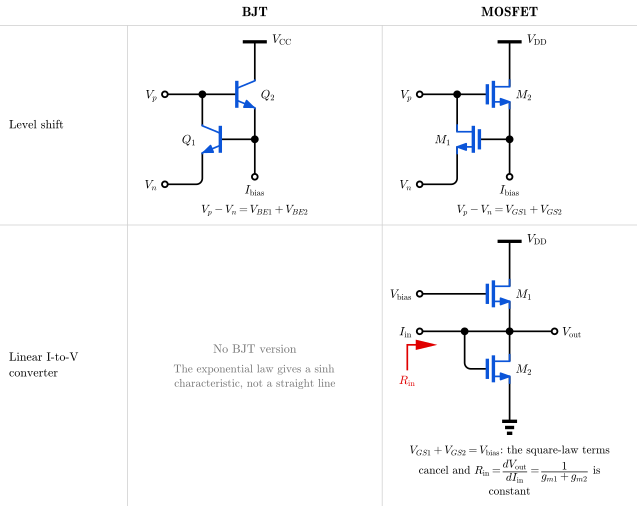

In [29]:
# HIDE/SHOW
def level_shift(c):
    """Level shift"""
    c.center(0)                                             # aligned on the route from the supply
    t2 = c.transistor('n', (0, 0), 'cd', name=2)
    c.supply((0, -20)); c.w((0, -20), t2.cd)
    node = (0, 100)
    c.w(t2.es, node); c.dot(node); c.w(node, (0, 150)); c.port((0, 150), 'I_bias', 'b')
    t1 = c.transistor('n', (-30, 100), 'bg', side='right', name=1)
    c.w(t1.bg, node)
    c.w(t1.cd, (t1.cd[0], 40)); c.dot((t1.cd[0], 40)); c.w((t1.cd[0], 40), (t1.cd[0] - 50, 40)); c.port((t1.cd[0] - 50, 40), 'V_p', 'l')
    c.w((t1.cd[0], 40), t2.bg)
    c.w(t1.es, (t1.es[0], 160), (t1.es[0] - 50, 160)); c.port((t1.es[0] - 50, 160), 'V_n', 'l')


def linear_i_to_v(c):
    """- | Linear I-to-V converter"""
    (t1, t2), (j,) = c.chain([('n', 1), ('n', 2)], 0, 0)
    c.supply((0, -20)); c.w((0, -20), t1.cd)
    g = (0, t2.es[1] + 20); c.gnd(g); c.w(t2.es, g)
    term, tx = -120, -60
    c.w(t1.bg, (term, t1.bg[1])); c.port((term, t1.bg[1]), 'V_bias', 'l')
    c.dot(j); c.w(j, (60, j[1])); c.port((60, j[1]), OUT, 'r')
    c.w(j, (term, j[1])); c.dot((tx, j[1])); c.port((term, j[1]), 'I_in', 'l'); c.look((term, j[1]), 'r', 'd', 'R_in')
    c.w((tx, j[1]), (tx, t2.bg[1]), t2.bg)

show(level_shift, linear_i_to_v, notes=[
    ('$V_p-V_n=V_{BE1}+V_{BE2}$',
     '$V_p-V_n=V_{GS1}+V_{GS2}$'),
    (r'The exponential law gives a $\sinh$ characteristic, not a straight line',
     r'$V_{GS1}+V_{GS2}=V_\mathrm{bias}$: the square-law terms cancel and $R_\mathrm{in}=\dfrac{dV_\mathrm{out}}{dI_\mathrm{in}}=\dfrac{1}{g_{m1}+g_{m2}}$ is constant')])

### Switched Circuits

One device is a switch or a diode. The other is a second switch or a capacitor.

#### Transmission Gate and Multiplexer

Pass devices connect or isolate two nodes. Two complementary devices in parallel make a switch for the full signal range. Two devices with a common output select one of two inputs.

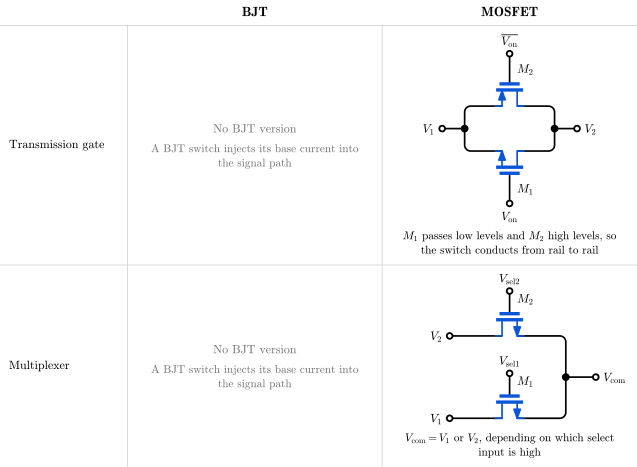

In [30]:
# HIDE/SHOW
def transmission_gate(c):
    """- | Transmission gate"""
    t1 = c.transistor('n', (0, 0), 'es', side='right', rot=1, name=1)
    t2 = c.transistor('p', (0, -60), 'es', side='right', rot=3, name=2)
    xl, xr = -20, 100
    c.w(t1.es, (xl, 0), (xl, -60), t2.es); c.dot((xl, -30)); c.w((xl, -30), (xl - 30, -30)); c.port((xl - 30, -30), 'V_1', 'l')
    c.w(t1.cd, (xr, 0), (xr, -60), t2.cd); c.dot((xr, -30)); c.w((xr, -30), (xr + 30, -30)); c.port((xr + 30, -30), 'V_2', 'r')
    c.w(t1.bg, (t1.bg[0], t1.bg[1] + 30)); c.port((t1.bg[0], t1.bg[1] + 30), 'V_on', 'b')
    c.w(t2.bg, (t2.bg[0], t2.bg[1] - 30)); c.port((t2.bg[0], t2.bg[1] - 30), '!V_on', 't')


def multiplexer(c):
    """- | Multiplexer"""
    t1 = c.transistor('n', (0, 0), 'cd', side='right', rot=3, name=1)
    t2 = c.transistor('n', (0, -110), 'cd', side='right', rot=3, name=2)
    for t, nm in ((t1, 'V_1'), (t2, 'V_2')):
        c.w(t.cd, (t.cd[0] - 40, t.cd[1])); c.port((t.cd[0] - 40, t.cd[1]), nm, 'l')
    c.w(t1.bg, (t1.bg[0], t1.bg[1] - 20)); c.port((t1.bg[0], t1.bg[1] - 20), 'V_sel1', 't')
    c.w(t2.bg, (t2.bg[0], t2.bg[1] - 20)); c.port((t2.bg[0], t2.bg[1] - 20), 'V_sel2', 't')
    xc, yc = 115, -55
    c.w(t1.es, (xc, 0), (xc, yc)); c.dot((xc, yc)); c.w(t2.es, (xc, -110), (xc, yc))
    c.w((xc, yc), (xc + 40, yc)); c.port((xc + 40, yc), 'V_com', 'r')

show(transmission_gate, multiplexer, notes=[
    ('A BJT switch injects its base current into the signal path',
     '$M_1$ passes low levels and $M_2$ high levels, so the switch conducts from rail to rail'),
    ('A BJT switch injects its base current into the signal path',
     r'$V_\mathrm{com}=V_1$ or $V_2$, depending on which select input is high')])

#### Sample-and-Hold and Low-Pass Filter

A pass device feeds a node that the second device loads as a capacitor. With a clock on the gate the circuit samples. With a fixed bias it filters.

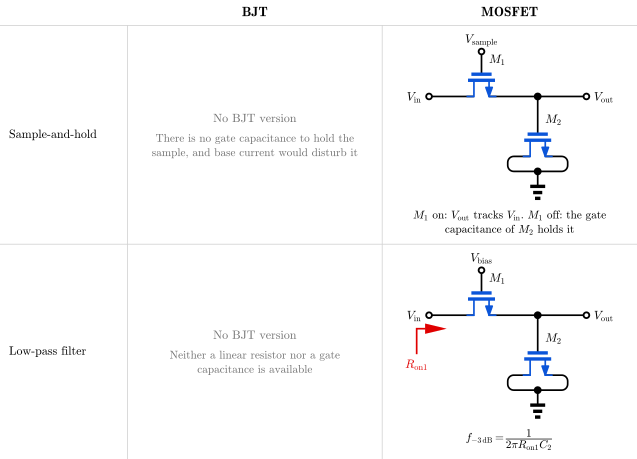

In [31]:
# HIDE/SHOW
def sample_and_hold(c):
    """- | Sample-and-hold"""
    pass_device_and_capacitor(c, 'V_sample')


def low_pass(c):
    """- | Low-pass filter"""
    pass_device_and_capacitor(c, 'V_bias', resistance='R_on1')

show(sample_and_hold, low_pass, notes=[
    ('There is no gate capacitance to hold the sample, and base current would disturb it',
     r'$M_1$ on: $V_\mathrm{out}$ tracks $V_\mathrm{in}$. $M_1$ off: the gate capacitance of $M_2$ holds it'),
    ('Neither a linear resistor nor a gate capacitance is available',
     r'$f_{-3\,\mathrm{dB}}=\dfrac{1}{2\pi R_\mathrm{on1}C_2}$')])

#### Peak Detector and Voltage Doubler

A diode-connected device and a capacitor-connected device rectify. Their order decides the function.

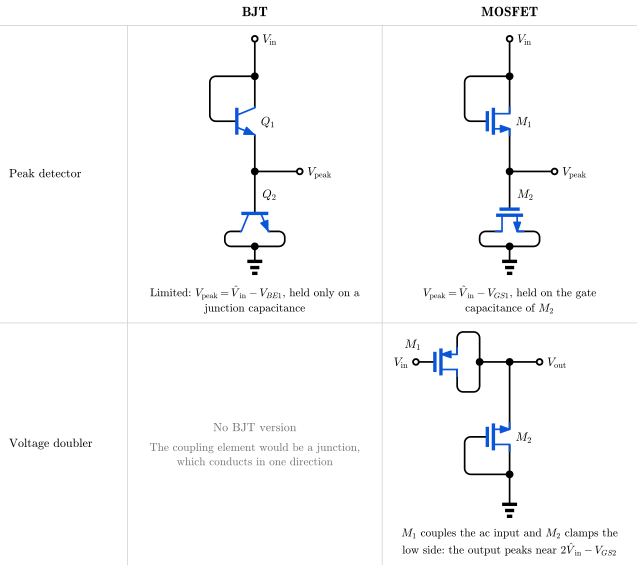

In [32]:
# HIDE/SHOW
def peak_detector(c):
    """Peak detector"""
    t1 = c.transistor('n', (0, 0), 'cd', name=1)
    top = (0, -20)
    c.w(t1.cd, top); c.dot(top); c.w(top, (0, -70)); c.port((0, -70), IN, 'r')
    c.w(top, (-60, -20), (-60, t1.bg[1]), t1.bg)
    pk = (0, 107)
    c.w(t1.es, pk); c.dot(pk); c.w(pk, (60, pk[1])); c.port((60, pk[1]), 'V_peak', 'r')
    capacitor_to_ground(c, pk)


def voltage_doubler(c):
    """- | Voltage doubler"""
    t1 = c.transistor('p', (0, 0), 'es')
    t1.name(1, 'l', dy=-24)                                # clear of the name of the input
    bar = 30
    c.w(t1.es, (bar, 0), (bar, 80), t1.cd)
    c.dot((bar, 40)); c.w((bar, 40), (110, 40)); c.port((110, 40), OUT, 'r')
    c.w(t1.bg, (-55, 40)); c.port((-55, 40), IN, 'l')
    t2 = c.transistor('n', (70, 100), 'es', side='right', rot=2, name=2, lbl='r')
    c.w(t2.es, (70, 40)); c.dot((70, 40))
    join = (70, t2.cd[1] + 10)                               # half-way between the transistor and the ground
    c.w(t2.cd, (70, join[1] + 30)); c.dot(join); c.gnd((70, join[1] + 30))
    c.w(t2.bg, (t2.bg[0] - 20, t2.bg[1]), (t2.bg[0] - 20, join[1]), join)
    c.center(70)                                            # aligned on the route to ground

show(peak_detector, voltage_doubler, notes=[
    (r'Limited: $V_\mathrm{peak}=\hat V_\mathrm{in}-V_{BE1}$, held only on a junction capacitance',
     r'$V_\mathrm{peak}=\hat V_\mathrm{in}-V_{GS1}$, held on the gate capacitance of $M_2$'),
    ('The coupling element would be a junction, which conducts in one direction',
     r'$M_1$ couples the ac input and $M_2$ clamps the low side: the output peaks near $2\hat V_\mathrm{in}-V_{GS2}$')])

### Logic Gates

Each device is a switch controlled by a logic level. In the mixer the logic levels give way to analog signals.

#### NAND and NOR

Two switches in series conduct only when both are on. Two switches in parallel conduct when either is on. The current source pulls the output high otherwise.

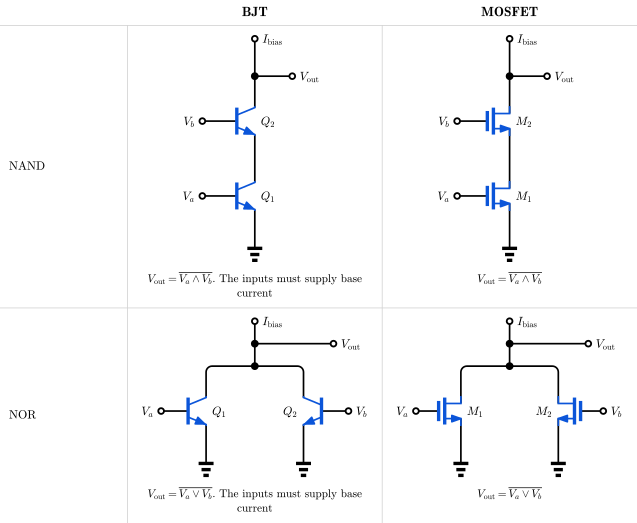

In [33]:
# HIDE/SHOW
def nand(c):
    """NAND"""
    (t2, t1), (j,) = c.chain([('n', 2), ('n', 1)], 0, 0)
    g = (0, t1.es[1] + 20); c.gnd(g); c.w(t1.es, g)
    for t, nm in ((t1, 'V_a'), (t2, 'V_b')):
        c.w(t.bg, (t.bg[0] - 30, t.bg[1])); c.port((t.bg[0] - 30, t.bg[1]), nm, 'l')
    top = (0, -20); c.w(t2.cd, top); c.dot(top); c.w(top, (50, top[1])); c.port((50, top[1]), OUT, 'r')
    c.w(top, (0, -70)); c.port((0, -70), 'I_bias', 'r')


def nor(c):
    """NOR"""
    t1 = c.transistor('n', (0, 0), 'cd', name=1)
    t2 = c.transistor('n', (130, 0), 'cd', side='right', name=2)
    for t in (t1, t2):
        g = (t.es[0], t.es[1] + 20); c.gnd(g); c.w(t.es, g)
    mx = 65
    c.w(t1.bg, (t1.bg[0] - 20, t1.bg[1])); c.port((t1.bg[0] - 20, t1.bg[1]), 'V_a', 'l')
    c.w(t2.bg, (t2.bg[0] + 20, t2.bg[1])); c.port((t2.bg[0] + 20, t2.bg[1]), 'V_b', 'r')
    yt = -20
    c.w(t1.cd, (0, yt), (130, yt)); c.w(t2.cd, (130, yt)); c.dot((mx, yt))
    top = (mx, -50); c.w((mx, yt), top); c.dot(top); c.w(top, (170, top[1])); c.port((170, top[1]), OUT, 'r')
    c.w(top, (mx, -80)); c.port((mx, -80), 'I_bias', 'r')

show(nand, nor, notes=[
    (r'$V_\mathrm{out}=\overline{V_a\wedge V_b}$. The inputs must supply base current',
     r'$V_\mathrm{out}=\overline{V_a\wedge V_b}$'),
    (r'$V_\mathrm{out}=\overline{V_a\vee V_b}$. The inputs must supply base current',
     r'$V_\mathrm{out}=\overline{V_a\vee V_b}$')])

#### XNOR and Mixer

Both circuits multiply. The XNOR gate multiplies two logic signs. The mixer multiplies two analog signals.

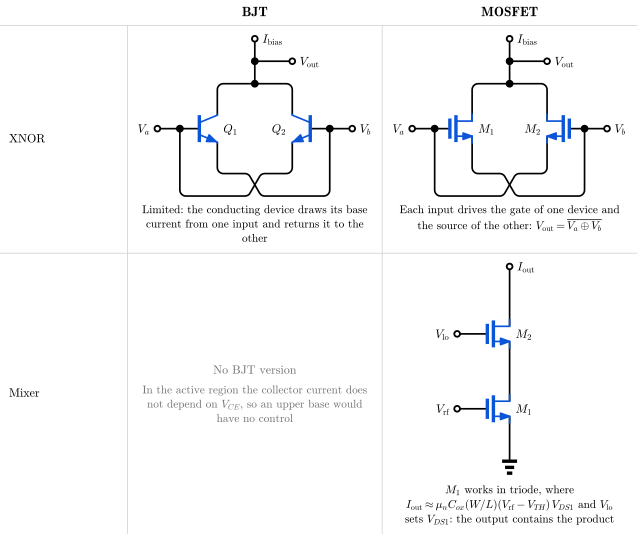

In [34]:
# HIDE/SHOW
def xnor(c):
    """XNOR"""
    t1 = c.transistor('n', (0, 0), 'cd', name=1)
    t2 = c.transistor('n', (100, 0), 'cd', side='right', name=2)
    mx = 50
    ga = (t1.bg[0] - 10, t1.bg[1]); gb = (t2.bg[0] + 10, t2.bg[1])
    c.w(t1.bg, ga); c.dot(ga); c.w(ga, (ga[0] - 30, ga[1])); c.port((ga[0] - 30, ga[1]), 'V_a', 'l')
    c.w(t2.bg, gb); c.dot(gb); c.w(gb, (gb[0] + 30, gb[1])); c.port((gb[0] + 30, gb[1]), 'V_b', 'r')
    yt = -20
    c.w(t1.cd, (0, yt), (mx, yt)); c.w(t2.cd, (100, yt), (mx, yt)); c.dot((mx, yt))
    c.w((mx, yt), (mx, -50)); c.dot((mx, -50)); c.w((mx, -50), (100, -50)); c.port((100, -50), OUT, 'r')
    c.w((mx, -50), (mx, -80)); c.port((mx, -80), 'I_bias', 'r')
    y1, y2 = t1.es[1] + 20, t1.es[1] + 50
    xl, xr = c.cross(mx, y1, y2)                            # the two wires cross as an X
    c.w(t1.es, (0, y1), (xl, y1), (xr, y2), (gb[0], y2), gb)
    c.w(t2.es, (100, y1), (xr, y1), (xl, y2), (ga[0], y2), ga)


def mixer(c):
    """- | Mixer"""
    (t2, t1), (j,) = c.chain([('n', 2), ('n', 1)], 0, 0)
    g = (0, t1.es[1] + 20); c.gnd(g); c.w(t1.es, g)
    c.w(t2.cd, (0, -50)); c.port((0, -50), 'I_out', 'r')
    c.w(t2.bg, (t2.bg[0] - 30, t2.bg[1])); c.port((t2.bg[0] - 30, t2.bg[1]), 'V_lo', 'l')
    c.w(t1.bg, (t1.bg[0] - 30, t1.bg[1])); c.port((t1.bg[0] - 30, t1.bg[1]), 'V_rf', 'l')

show(xnor, mixer, notes=[
    ('Limited: the conducting device draws its base current from one input and returns it to the other',
     r'Each input drives the gate of one device and the source of the other: $V_\mathrm{out}=\overline{V_a\oplus V_b}$'),
    ('In the active region the collector current does not depend on $V_{CE}$, so an upper base would have no control',
     r'$M_1$ works in triode, where $I_\mathrm{out}\approx\mu_nC_{ox}(W/L)(V_\mathrm{rf}-V_{TH})\,V_{DS1}$ and $V_\mathrm{lo}$ sets $V_{DS1}$: the output contains the product')])

## Connections of More Transistors

### Building a Two-Stage Op Amp

Each row adds one block from the sections above to the circuit of the row before. The gain is $A_v=V_\mathrm{out}/(V_1-V_2)$.

#### Pair and Tail Source

The differential pair is one of the feedback pairs. The current source in its tail is one of the eight roles.

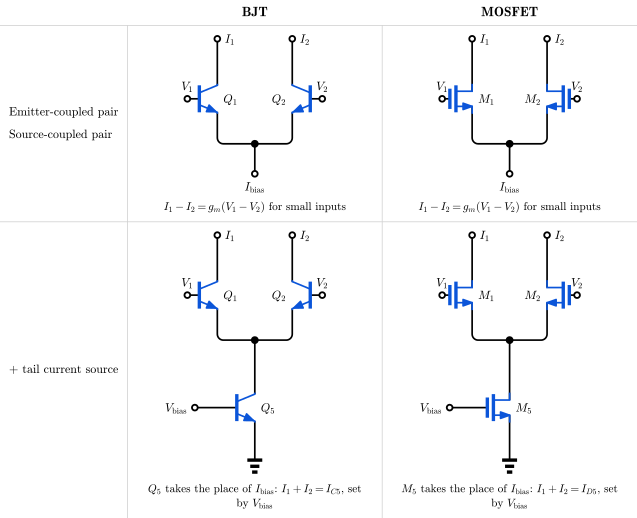

In [35]:
# HIDE/SHOW
def op_amp_pair(c):
    """Emitter-coupled pair | Source-coupled pair"""
    op_amp(c, 1)


def op_amp_tail(c):
    """+ tail current source"""
    op_amp(c, 2)

show(op_amp_pair, op_amp_tail, notes=[
    '$I_1-I_2=g_m(V_1-V_2)$ for small inputs',
    (r'$Q_5$ takes the place of $I_\mathrm{bias}$: $I_1+I_2=I_{C5}$, set by $V_\mathrm{bias}$',
     r'$M_5$ takes the place of $I_\mathrm{bias}$: $I_1+I_2=I_{D5}$, set by $V_\mathrm{bias}$')])

#### Mirror Load and Second Stage

The current mirror is one of the bias circuits. The second stage is the active-load stage of the gain stages, with the two types swapped.

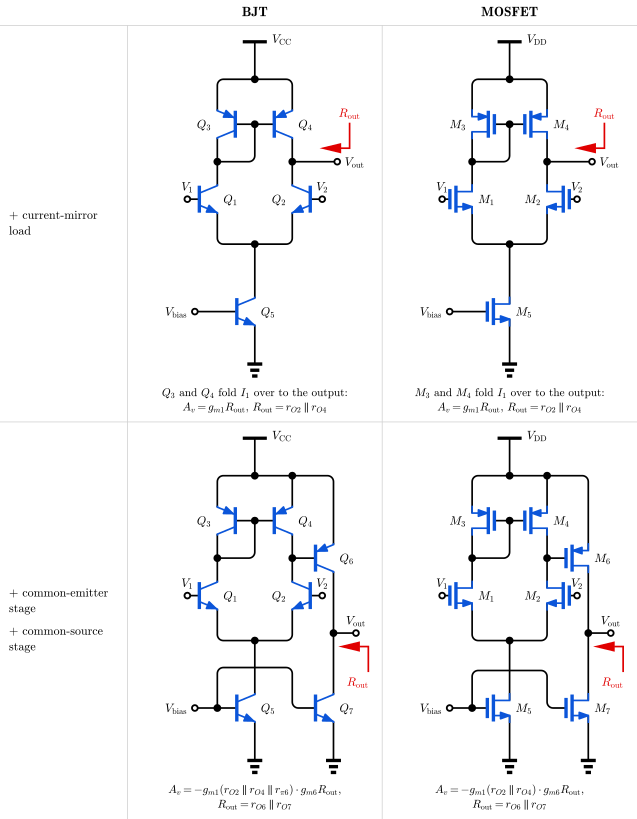

In [36]:
# HIDE/SHOW
def op_amp_mirror(c):
    """+ current-mirror load"""
    op_amp(c, 3)


def op_amp_second(c):
    """+ common-emitter stage | + common-source stage"""
    op_amp(c, 4)

show(op_amp_mirror, op_amp_second, notes=[
    (r'$Q_3$ and $Q_4$ fold $I_1$ over to the output: $A_v=g_{m1}R_\mathrm{out}$, $R_\mathrm{out}=r_{O2}\parallel r_{O4}$',
     r'$M_3$ and $M_4$ fold $I_1$ over to the output: $A_v=g_{m1}R_\mathrm{out}$, $R_\mathrm{out}=r_{O2}\parallel r_{O4}$'),
    (r'$A_v=-g_{m1}(r_{O2}\parallel r_{O4}\parallel r_{\pi6})\cdot g_{m6}R_\mathrm{out}$, $R_\mathrm{out}=r_{O6}\parallel r_{O7}$',
     r'$A_v=-g_{m1}(r_{O2}\parallel r_{O4})\cdot g_{m6}R_\mathrm{out}$, $R_\mathrm{out}=r_{O6}\parallel r_{O7}$')])

#### Bias Mirror

A second current mirror supplies both bias currents from one reference current.

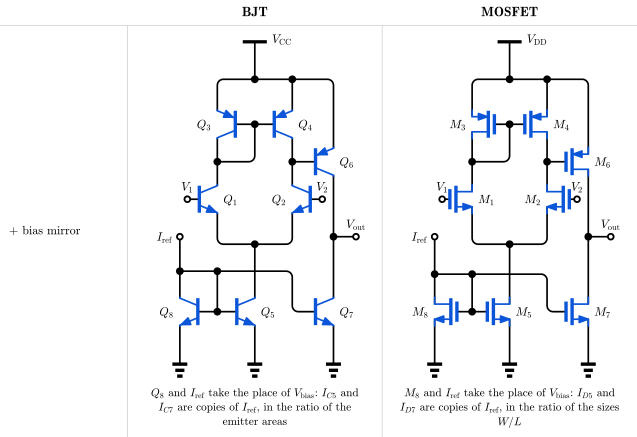

In [37]:
# HIDE/SHOW
def op_amp_bias(c):
    """+ bias mirror"""
    op_amp(c, 5)

show(op_amp_bias, notes=[
    (r'$Q_8$ and $I_\mathrm{ref}$ take the place of $V_\mathrm{bias}$: $I_{C5}$ and $I_{C7}$ are copies of $I_\mathrm{ref}$, in the ratio of the emitter areas',
     r'$M_8$ and $I_\mathrm{ref}$ take the place of $V_\mathrm{bias}$: $I_{D5}$ and $I_{D7}$ are copies of $I_\mathrm{ref}$, in the ratio of the sizes $W/L$')])

## Symbols

The symbol library behind the drawings, at one scale. This page uses the transistors, the resistor, the ground, the supply rail, the terminal and the node dot. The BJT and the MOSFET share one footprint, so the two versions of every circuit line up.

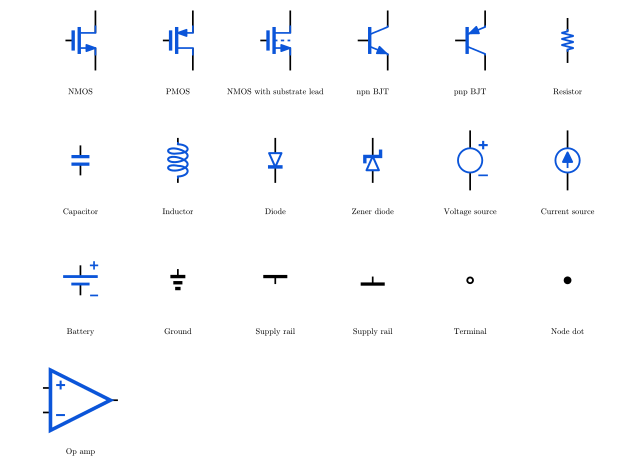

In [38]:
# HIDE/SHOW
symbol_sheet()